# BVG Berlin bus electrification: Berlin line and depot model
**IE Sustainability Datathon 2026 (Kearney).** This notebook replicates the Madrid model (`Madrid/data/madrid_model_clean.ipynb`) for **Berlin (BVG)**: timetable, daily km, buses, energy, charging strategy, depot allocation, and Files 2, 3 and 4. It also writes Berlin's File 1 row.

**How to read it.** Same conventions as Madrid: every section opens with a short text cell, then code, then a printed check. Provenance labels: **V** verified from a cited source, **D** derived transparently from source data, **P** proxy from indirect evidence, **A** explicit assumption. The assumptions register (Section 11) collects them. Sources are listed in `Berlin/data/README.md`.

**What is different from Madrid, and why.** Berlin has no EMT-style supply file, no vehicle-level fleet history and no line-to-depot table. Each gap is replaced by a transparent rule:

| Madrid input | Berlin replacement | Label |
|---|---|---|
| EMT supply file (`NumCCReal`) for `peak_buses` | Peak concurrent trips per line in the GTFS, plus a 5-minute terminus layover (Helsinki method) | P |
| Fleet history (one row per vehicle) | BVG in Zahlen 2025, fleet at 31 Dec 2025 by type | V |
| Passengers per bus for the articulated proxy | Line type (MetroBus, Express, trunk 100/200/300) and peak buses | P / A |
| Historical depot code per line | Capacity-constrained nearest depot, using depot positions from GTFS depot stops | P |
| CNG (kg/km, MITECO factor) | Diesel (l/km from the federal e-bus evaluation; BVG's own CO2 factor) | V |
| Connection MW (3 of 5 documented) | Stromnetz Berlin allocation range 10-13 MVA per depot; Indira-Gandhi-Straße 10 MW documented | V / P |
| La Elipa closed and reopening (cases A/B) | Two new e-bus depots (Säntisstraße, Treptow) opening 2027: case B = today's 6 depots, case A = 8-depot end state | V / P |

**Time points:** fleet baseline **31 Dec 2025**; timetable and km on the GTFS **reference day 2026-11-24** (Tuesday).

**Contents:** 1 Setup, 2 Load data, 3 Reference date, 4 Daily km, 5 Peak buses, 6 Fleet baseline, 7 File 2 core, 8 Sensitivities, 9 Depot allocation, 10 Emissions, priority and File 2, 10c File 3, 10d File 4, 10e Figures, 10f File 1 row and benchmark, 11 Assumptions register, 12 Regression checks, 13 Open items.

## 1. Setup
All dates and parameters are defined once here. The energy, range, charger, window and efficiency parameters are the brief's fixed values (Section 4.5), kept identical to Madrid so that both cities are comparable. Berlin-specific inputs are sourced in the comments.

In [1]:
import os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 110)

# ---- analysis dates ----
REFERENCE_DATE = '2026-11-24'    # GTFS reference day (Tuesday), same day as the Helsinki benchmark
BASELINE_DATE  = '2025-12-31'    # fleet baseline (File 1, File 4)
ALLOC_CASE     = 'A'             # 'A' = end state with the two new e-bus depots (base, Files 2 and 3); 'B' = today's six depots
NEW_DEPOTS_OPEN = 2027           # Säntisstraße and Treptow: opening planned April 2027 (BVG / Senate, S19/22944)
ref = pd.Timestamp(REFERENCE_DATE)

# ---- fixed parameters from the brief (Section 4.5), identical to Madrid ----
FIXED = dict(kwh_std=1.30, kwh_art=1.85, range_std=300, range_art=240,
             charger_kw=100, window_h=7, eff=0.90, annual_days=365)
KWH   = {'Standard': FIXED['kwh_std'],   'Articulated': FIXED['kwh_art']}
LIMIT = {'Standard': FIXED['range_std'], 'Articulated': FIXED['range_art']}

# ---- team assumptions (class A), as in Madrid ----
OPP_MAX = 2.0          # Opportunity charging accepted up to 2.0 x the effective daily range
MIN_BUSES_ART = 5      # articulated proxy only considers lines with at least this many peak buses
LAYOVER_MIN = 5        # terminus layover added to every trip when counting vehicles in service (Helsinki method)

# ---- diesel and emission factors ----
DIESEL_L_KM = {'Standard': 0.37, 'Articulated': 0.50}   # V: federal e-bus funding evaluation (BMWK, Dec 2024), table 39, p. 375
DIESEL_CO2_KG_PER_L = 3.236     # V: BVG Nachhaltigkeitsbericht 2025, p. 42 (well-to-wheel, 5% biodiesel, UBA 2022)
ELEC_CO2_KG_PER_KWH = 0.344     # V: Umweltbundesamt, German electricity mix 2025 (344 g/kWh)

# ---- S1 sequencing (class A, identical to Madrid) ----
W_IMPACT = 0.5
S1_RAMP = {2026: 0.05, 2027: 0.30, 2028: 0.54, 2029: 0.78, 2030: 1.00}

# ---- File 3: grid connection ----
CONN_SCENARIO = 'low'                       # 'low' | 'high'
CONN_MVA = {'low': 10.0, 'high': 13.0}      # V/P: Stromnetz Berlin allocation, every BVG bus depot needs 10-13 MVA (Senate report h19-2626, 19 Jan 2026); MVA treated as MW
EVIDENCED_CONN_MW = {'Indira-Gandhi-Straße': 10.0}   # V: NOW GmbH project brochure 2020, new 10 MW medium-voltage connection

DATA_DIR = Path('data'); OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
print('Reference day:', REFERENCE_DATE, ref.day_name(), '| baseline:', BASELINE_DATE, '| allocation case:', ALLOC_CASE, '| connection scenario:', CONN_SCENARIO)

Reference day: 2026-11-24 Tuesday | baseline: 2025-12-31 | allocation case: A | connection scenario: low


## 2. Load the data
**Source.** VBB GTFS feed (Verkehrsverbund Berlin-Brandenburg open data), downloaded **2026-11-18**, valid 2026-11-18 to 2027-12-11: https://vbb.de/vbb-services/api-open-data/datensaetze/

The full feed is about 640 MB (stop_times alone is 400 MB), too large for the repository. `data/make_gtfs_extract.py` reduces it to what this model needs: agency **796 (Berliner Verkehrsbetriebe)**, `route_type` **700 (bus)**, all their trips and calendars, and the stop times and shapes of the trips active on the reference day. The extract (8 MB) is committed in `data/`. Rerun the script on a fresh download to change the reference day.

Perimeter: BVG bus lines only. Trams, U-Bahn, ferries and other VBB operators are excluded. Lines run by BVG subcontractors (about 8% of bus service) are included because they appear under agency 796.

In [2]:
gtfs_zip = DATA_DIR / 'vbb_gtfs_bvg_bus_extract.zip'
with zipfile.ZipFile(gtfs_zip) as z:
    print('Files in the extract:', z.namelist())
    gtfs = {n[:-4]: pd.read_csv(z.open(n), dtype=str) for n in z.namelist() if n.endswith('.txt') and n != 'README.txt'}
for name, df in gtfs.items():
    print(f'{name:16s} rows={len(df):>9,}  cols={list(df.columns)}')
routes, trips = gtfs['routes'], gtfs['trips']
assert set(routes.agency_id) == {'796'} and set(routes.route_type) == {'700'}

Files in the extract: ['agency.txt', 'routes.txt', 'trips.txt', 'calendar.txt', 'calendar_dates.txt', 'stop_times.txt', 'shapes.txt', 'stops.txt', 'README.txt']


agency           rows=        1  cols=['agency_id', 'agency_name', 'agency_url', 'agency_timezone', 'agency_lang', 'agency_phone']
routes           rows=      223  cols=['route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_type', 'route_color', 'route_text_color', 'route_desc']
trips            rows=  130,532  cols=['route_id', 'service_id', 'trip_id', 'trip_headsign', 'trip_short_name', 'direction_id', 'block_id', 'shape_id', 'wheelchair_accessible', 'bikes_allowed']
calendar         rows=      233  cols=['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']
calendar_dates   rows=    5,171  cols=['service_id', 'date', 'exception_type']
stop_times       rows=  702,886  cols=['trip_id', 'stop_id', 'stop_sequence', 'pickup_type', 'drop_off_type', 'stop_headsign', 'arrival_time', 'departure_time']
shapes           rows=  289,319  cols=['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence']
stops   

## 3. Reference date: is it valid in the GTFS feed?
The reference day must be a Tuesday or Wednesday, a regular working day outside holidays, and inside the validity window of the feed. **2026-11-24** is a Tuesday, outside Berlin school holidays (autumn break ended 31 Oct) and has no public holiday (Buß- und Bettag on 18 Nov is a holiday only in Saxony). Both `calendar.txt` and `calendar_dates.txt` are applied. A similar trip count on nearby weekdays shows the day is representative. Strikes cannot be verified for a future date: re-check once the day has passed (A).

In [3]:
cal, cd = gtfs['calendar'], gtfs['calendar_dates']
print('calendar.txt range:', cal.start_date.min(), '->', cal.end_date.max())

def active_services(d):
    d = pd.Timestamp(d); ds = d.strftime('%Y%m%d'); dw = d.day_name().lower()
    s = set(cal[(cal[dw] == '1') & (cal.start_date <= ds) & (cal.end_date >= ds)].service_id)
    e = cd[cd.date == ds]
    s |= set(e.loc[e.exception_type == '1', 'service_id']); s -= set(e.loc[e.exception_type == '2', 'service_id'])
    return s

assert cal.start_date.min() <= ref.strftime('%Y%m%d') <= cal.end_date.max(), 'reference day outside the feed'
t_ref = trips[trips.service_id.isin(active_services(ref))].merge(routes[['route_id', 'route_short_name']], on='route_id')
print('Trips on the reference day:', len(t_ref), '| lines with at least one trip:', t_ref.route_short_name.nunique(), 'of', routes.route_short_name.nunique())
print('Trips with a block_id:', int(t_ref.block_id.notna().sum()), '(too few to rebuild vehicle blocks, see Section 5)')
print('\nNearby weekdays (similar counts = representative day):')
for d in ['2026-11-18', '2026-11-19', REFERENCE_DATE, '2026-11-25', '2026-12-01', '2026-12-02']:
    print(' ', d, pd.Timestamp(d).day_name()[:3], '-> trips:', int(trips.service_id.isin(active_services(d)).sum()))

calendar.txt range: 20261118 -> 20271211
Trips on the reference day: 29209 | lines with at least one trip: 215 of 223
Trips with a block_id: 3649 (too few to rebuild vehicle blocks, see Section 5)

Nearby weekdays (similar counts = representative day):
  2026-11-18 Wed -> trips: 29207
  2026-11-19 Thu -> trips: 29209
  2026-11-24 Tue -> trips: 29209
  2026-11-25 Wed -> trips: 29207
  2026-12-01 Tue -> trips: 29288
  2026-12-02 Wed -> trips: 29284


## 4. Daily in-service km per line
**Method (D).** The VBB feed has no `shape_dist_traveled`, so each trip's length is the **geodesic (haversine) length of its shape**. Independent check: the straight-line distance between consecutive stops must be slightly shorter than the shape (streets are not straight). Daily km per line is the sum over its trips.

`frequencies.txt` in the full feed contains only its header, so there is no double counting risk. **In-service km only**: deadheading between depot and line is not in the GTFS (A, same limitation as Madrid).

In [4]:
def haversine(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))

sh = gtfs['shapes'].copy()
sh['lat'] = sh.shape_pt_lat.astype(float); sh['lon'] = sh.shape_pt_lon.astype(float); sh['seq'] = sh.shape_pt_sequence.astype(int)
sh = sh.sort_values(['shape_id', 'seq'])
same = sh.shape_id.values[:-1] == sh.shape_id.values[1:]
sh['seg'] = np.r_[0.0, np.where(same, haversine(sh.lat.values[:-1], sh.lon.values[:-1], sh.lat.values[1:], sh.lon.values[1:]), 0.0)]
shape_km = sh.groupby('shape_id').seg.sum().rename('shape_km')

stops = gtfs['stops'].copy(); stops['lat'] = stops.stop_lat.astype(float); stops['lon'] = stops.stop_lon.astype(float)
st = gtfs['stop_times'].copy()
st['seq'] = st.stop_sequence.astype(int); st = st.sort_values(['trip_id', 'seq']).merge(stops[['stop_id', 'lat', 'lon']], on='stop_id', how='left')
s2 = st.trip_id.values[:-1] == st.trip_id.values[1:]
st['seg'] = np.r_[0.0, np.where(s2, haversine(st.lat.values[:-1], st.lon.values[:-1], st.lat.values[1:], st.lon.values[1:]), 0.0)]
def to_min(s):
    p = s.str.split(':', expand=True).astype(int)
    return p[0] * 60 + p[1] + p[2] / 60
st['dep'] = to_min(st.departure_time); st['arr'] = to_min(st.arrival_time)
g = st.groupby('trip_id')
trip = pd.DataFrame({'stop_km': g.seg.sum(), 'start': g.dep.min(), 'end': g.arr.max(),
                     'first_lat': g.lat.first(), 'first_lon': g.lon.first(), 'last_lat': g.lat.last(), 'last_lon': g.lon.last()})
tt = t_ref.merge(trip, left_on='trip_id', right_index=True).merge(shape_km, left_on='shape_id', right_index=True, how='left')
assert len(tt) == len(t_ref) and tt.shape_km.notna().all(), 'every reference-day trip needs stop times and a shape'
tt['km'] = tt.shape_km
r = tt.stop_km / tt.shape_km
print(f'Trips: {len(tt)} | stop-to-stop / shape length: median {r.median():.3f}, 5th pct {r.quantile(.05):.3f}, 95th pct {r.quantile(.95):.3f} (below 1 as expected)')

daily = (tt.groupby('route_short_name')
           .agg(trips=('trip_id', 'count'), daily_km=('km', 'sum'), first_dep=('start', 'min'), last_arr=('end', 'max'))
           .reset_index())
daily['service_hours'] = tt.groupby('route_short_name').apply(lambda x: ((x.end - x.start).sum()) / 60).values
print('Lines:', len(daily), '| total daily km:', round(daily.daily_km.sum()))
print('Cross-check: BVG reports 89.7 million bus vehicle-km in 2025 (BVG in Zahlen 2025) = %.0f km per average day; '
      'a weekday sits above the yearly average because weekends run less service.' % (89.7e6 / 365))
REPLACEMENT = sorted(l for l in daily.route_short_name if l in {'12', '21', '27', '60', '61', 'M8', 'M17', 'U2', 'U6'})
print('Rail-replacement bus services on the reference day (tram / U-Bahn line numbers, kept in the model, flagged):', REPLACEMENT)

Trips: 29209 | stop-to-stop / shape length: median 0.932, 5th pct 0.838, 95th pct 0.981 (below 1 as expected)
Lines: 215 | total daily km: 291764
Cross-check: BVG reports 89.7 million bus vehicle-km in 2025 (BVG in Zahlen 2025) = 245753 km per average day; a weekday sits above the yearly average because weekends run less service.
Rail-replacement bus services on the reference day (tram / U-Bahn line numbers, kept in the model, flagged): ['12', '21', '27', 'M17', 'M8', 'U2', 'U6']


## 5. Peak buses per line (GTFS proxy)
Madrid takes `peak_buses` from EMT's supply file. Berlin has no equivalent, and only 12% of the reference-day trips carry a `block_id`, so vehicle blocks cannot be rebuilt (as in the Brussels notebook). We use the **Helsinki method (P)**: count each line's **concurrent trips minute by minute**, with a **5-minute terminus layover** added after every trip; `peak_buses` is the maximum of that curve.

It is a **lower bound** per line (longer layovers, driver breaks and spare vehicles are ignored), so `km_per_bus_day` is an upper bound, which makes the charging test conservative. The sensitivity with 10 and 15 minutes is printed. Reconciliation: the sum of the line peaks is compared with the BVG fleet.

In [5]:
def curve(df, layover):
    n = int(df.end.max() + layover) + 3
    d = np.zeros(n + 1)
    np.add.at(d, np.floor(df.start.values).astype(int), 1)
    np.add.at(d, np.ceil(df.end.values + layover).astype(int), -1)
    return np.cumsum(d)[:n]

peak = {lay: tt.groupby('route_short_name').apply(lambda x: int(curve(x, lay).max())) for lay in (0, 5, 10, 15)}
net = {lay: int(curve(tt, lay).max()) for lay in (0, 5, 10, 15)}
for lay in (0, 5, 10, 15):
    print(f'layover {lay:2d} min: sum of line peaks {peak[lay].sum():5d} | network peak (all lines at the same minute) {net[lay]:5d}')
daily['peak_buses'] = daily.route_short_name.map(peak[LAYOVER_MIN]).clip(lower=1).astype(int)
FLEET_TOTAL_CHECK = 1532
print(f'\nChosen: {LAYOVER_MIN}-minute layover -> sum of line peaks {daily.peak_buses.sum()} vs BVG fleet {FLEET_TOTAL_CHECK} (31 Dec 2025).')
print('Lines peak at different times, so the sum of line peaks is above the network peak; with interlining between lines the real requirement sits in between.')
vc = pd.DataFrame({'minute': np.arange(len(curve(tt, LAYOVER_MIN))), 'vehicles': curve(tt, LAYOVER_MIN)})
vc.to_csv(OUT_DIR / 'berlin_vehicles_by_minute.csv', index=False)

layover  0 min: sum of line peaks  1381 | network peak (all lines at the same minute)  1019
layover  5 min: sum of line peaks  1572 | network peak (all lines at the same minute)  1165
layover 10 min: sum of line peaks  1748 | network peak (all lines at the same minute)  1310
layover 15 min: sum of line peaks  1929 | network peak (all lines at the same minute)  1464

Chosen: 5-minute layover -> sum of line peaks 1572 vs BVG fleet 1532 (31 Dec 2025).
Lines peak at different times, so the sum of line peaks is above the network peak; with interlining between lines the real requirement sits in between.


## 6. Fleet baseline at 31 December 2025
No vehicle-level history is published for BVG. The baseline is the official **BVG in Zahlen 2025** (V): 1,532 buses = 202 single-deck + 838 articulated and 15 m + 199 double-deck + 277 electric + 16 special vehicles. The BVG Sustainability Report 2025 gives 278 e-buses (about 18%); 277 is used because it pairs with the 1,532 total.

Of the 277 e-buses, **67 are articulated** (17 Solaris Urbino 18 on line 200 and 50 Urbino 18 delivered in 2025; federal evaluation p. 301 and BVG press release 13 Jan 2025), so 210 are 12 m (D). Non-electric buses are diesel; the 16 special vehicles are counted as diesel (A). There are no hydrogen buses.

In [6]:
FLEET = {'single_deck': 202, 'articulated_15m': 838, 'double_deck': 199, 'electric': 277, 'special': 16}
FLEET_TOTAL = sum(FLEET.values()); assert FLEET_TOTAL == 1532
N_BEV, N_H2 = FLEET['electric'], 0
N_DIESEL = FLEET_TOTAL - N_BEV - N_H2
E_ART = 17 + 50
LARGE = FLEET['articulated_15m'] + FLEET['double_deck'] + E_ART           # vehicles above 12 m or double-deck
REGULAR = FLEET_TOTAL - FLEET['special']
ART_SHARE_FLEET = LARGE / REGULAR
print(f'Fleet {FLEET_TOTAL}: BEV {N_BEV} + H2 {N_H2} + diesel {N_DIESEL} | zero-emission share {100*N_BEV/FLEET_TOTAL:.1f}%')
print(f'Large vehicles (articulated, 15 m, double-deck, incl. {E_ART} e-articulated): {LARGE} of {REGULAR} regular buses = {100*ART_SHARE_FLEET:.1f}%')
published = pd.DataFrame([
    ['BVG in Zahlen 2025 (31 Dec 2025)', 1532, 277, 'chosen baseline (V)', 'https://www.bvg.de/dam/jcr:b7825abf-7399-4ead-bdd1-5d315d94808a/BVG-in-Zahlen-2025.pdf'],
    ['BVG Nachhaltigkeitsbericht 2025, p. 39', None, 278, 'about 18% of the fleet', 'https://www.bvg.de/dam/jcr:99b45b88-6814-4f3e-959d-6ef440adf229/BVG-Nachhaltigkeitsbericht-2025.pdf'],
    ['electrive, 18 Mar 2026', 1500, 280, 'rounded', 'https://www.electrive.net/2026/03/18/bvg-zelebriert-richtfest-am-elektrobus-depot-in-marienfelde/'],
], columns=['source', 'total', 'bev', 'note', 'url'])
print(published[['source', 'total', 'bev', 'note']].to_string(index=False))

Fleet 1532: BEV 277 + H2 0 + diesel 1255 | zero-emission share 18.1%
Large vehicles (articulated, 15 m, double-deck, incl. 67 e-articulated): 1104 of 1516 regular buses = 72.8%
                                source  total  bev                   note
      BVG in Zahlen 2025 (31 Dec 2025) 1532.0  277    chosen baseline (V)
BVG Nachhaltigkeitsbericht 2025, p. 39    NaN  278 about 18% of the fleet
                electrive, 18 Mar 2026 1500.0  280                rounded


## 7. File 2 core: buses, energy and charging strategy
Per line: `daily_km`, `peak_buses`, `km_per_bus_day = daily_km / peak_buses`, `bus_type`, `energy_kwh_bus_day` (fixed 1.30 or 1.85 kWh/km) and `charging_strategy`.

* **Bus type (P/A).** The brief has two types. Articulated, 15 m and double-deck buses are all treated as `Articulated` (1.85 kWh/km, 240 km). They are 72.8% of BVG's regular fleet, so lines are flagged `Articulated` until their peak buses reach that share. No passenger data per line is open, so the ranking uses line type, then size: MetroBus (`M`), Express (`X`) and the city trunk lines 100, 200, 300 first, then other day lines with at least `MIN_BUSES_ART` peak buses, by peak buses. Night lines (`N`) stay `Standard` (A). Validation points: line 200 runs articulated e-buses; lines 142, 259 and 347 run 12 m e-buses (federal evaluation, p. 299).
* **Charging strategy (rule 2 of the brief)**, identical to Madrid: `Depot` up to 300 km (Standard) or 240 km (Articulated), `Opportunity` up to `OPP_MAX` times, otherwise `Not_feasible`.

In [7]:
f2 = daily.rename(columns={'route_short_name': 'line_id'}).copy()
f2['km_per_bus_day'] = f2.daily_km / f2.peak_buses

def line_group(l):
    if l.startswith(('M', 'X')) or l in ('100', '200', '300'):
        return 0                                   # MetroBus, Express, city trunk lines
    if l.startswith('N'):
        return 9                                   # night lines: Standard
    return 1
f2['group'] = f2.line_id.map(line_group)
target = round(ART_SHARE_FLEET * f2.peak_buses.sum())
cand = f2[(f2.group < 9) & ((f2.group == 0) | (f2.peak_buses >= MIN_BUSES_ART))].sort_values(['group', 'peak_buses'], ascending=[True, False]).copy()
cand['cum'] = cand.peak_buses.cumsum()
art_codes = set(cand[cand.cum <= target].line_id)
f2['bus_type'] = np.where(f2.line_id.isin(art_codes), 'Articulated', 'Standard')
covered = int(f2.loc[f2.bus_type == 'Articulated', 'peak_buses'].sum())
print(f'Articulated target: {100*ART_SHARE_FLEET:.1f}% of {f2.peak_buses.sum()} peak buses = {target} | lines flagged: {len(art_codes)} | peak buses covered: {covered}')
for l, expect in [('200', 'Articulated'), ('142', 'Standard'), ('259', 'Standard'), ('347', 'Standard')]:
    got = f2.loc[f2.line_id == l, 'bus_type'].iloc[0]
    print(f'  validation line {l}: {got} (expected {expect})', 'OK' if got == expect else 'MISMATCH')

f2['energy_kwh_bus_day'] = f2.km_per_bus_day * f2.bus_type.map(KWH)
f2['range_km'] = f2.bus_type.map(LIMIT)
f2['over_range'] = f2.km_per_bus_day > f2.range_km
def strategy(r, k=OPP_MAX):
    if r.km_per_bus_day <= r.range_km:
        return 'Depot'
    return 'Opportunity' if r.km_per_bus_day <= k * r.range_km else 'Not_feasible'
f2['charging_strategy'] = f2.apply(strategy, axis=1)
f2['hours_per_bus'] = f2.service_hours / f2.peak_buses
print('\nLines:', len(f2), '| total daily km:', round(f2.daily_km.sum()), '| total peak buses:', int(f2.peak_buses.sum()))
print('Bus types:', f2.bus_type.value_counts().to_dict(), '| charging strategy:', f2.charging_strategy.value_counts().to_dict())
print('\nLines above their effective range:')
print(f2[f2.over_range].sort_values('km_per_bus_day', ascending=False)[['line_id', 'daily_km', 'peak_buses', 'km_per_bus_day', 'bus_type', 'charging_strategy']].round(1).to_string(index=False))

Articulated target: 72.8% of 1572 peak buses = 1145 | lines flagged: 102 | peak buses covered: 1145
  validation line 200: Articulated (expected Articulated) OK
  validation line 142: Standard (expected Standard) OK
  validation line 259: Standard (expected Standard) OK
  validation line 347: Standard (expected Standard) OK

Lines: 215 | total daily km: 291764 | total peak buses: 1572
Bus types: {'Standard': 113, 'Articulated': 102} | charging strategy: {'Depot': 198, 'Opportunity': 17}

Lines above their effective range:
line_id  daily_km  peak_buses  km_per_bus_day    bus_type charging_strategy
    X71    2399.2           6           399.9 Articulated       Opportunity
     X7    1077.4           3           359.1 Articulated       Opportunity
    893     686.8           2           343.4    Standard       Opportunity
    X69    2045.8           6           341.0 Articulated       Opportunity
    X36    1545.6           5           309.1 Articulated       Opportunity
    M21    3008.

## 8. Sensitivities required by the brief
1. **Opportunity-charging limit** (1.5x, 2.0x, 2.5x the range).
2. **Vehicle-block proxy.** Madrid's alternative uses the median buses over the day; here the alternative is a longer **terminus layover** (10 and 15 minutes), which gives more buses per line and fewer km per bus, and the stricter **no-layover** case (0 minutes), which gives the most km per bus.
3. **Bus type.** All lines `Standard` (the Helsinki benchmark convention) and all lines `Articulated`.

In [8]:
print('1) Opportunity limit:')
for k in [1.5, 2.0, 2.5]:
    print(f'   {k}x range ->', f2.apply(strategy, axis=1, k=k).value_counts().to_dict())

print('\n2) Layover used for peak_buses:')
rows = []
for lay in (0, 5, 10, 15):
    pb = f2.line_id.map(peak[lay]).clip(lower=1)
    kpb = f2.daily_km / pb
    s = pd.Series([('Depot' if a <= b else 'Opportunity' if a <= OPP_MAX * b else 'Not_feasible') for a, b in zip(kpb, f2.range_km)])
    rows.append({'layover_min': lay, 'sum_peak_buses': int(pb.sum()), 'median_km_per_bus': round(kpb.median(), 1),
                 'lines_over_range': int((kpb > f2.range_km).sum()), **s.value_counts().to_dict()})
sens_layover = pd.DataFrame(rows).fillna(0); print(sens_layover.to_string(index=False))

print('\n3) Bus type:')
for bt in ['Standard', 'Articulated']:
    over = (f2.km_per_bus_day > LIMIT[bt]).sum()
    print(f'   all {bt:11s}: lines over range {over} | network energy {f2.daily_km.sum() * KWH[bt] / 1000:.0f} MWh/day '
          f'(base mix {(f2.peak_buses * f2.energy_kwh_bus_day).sum() / 1000:.0f} MWh/day)')

1) Opportunity limit:
   1.5x range -> {'Depot': 198, 'Opportunity': 16, 'Not_feasible': 1}
   2.0x range -> {'Depot': 198, 'Opportunity': 17}
   2.5x range -> {'Depot': 198, 'Opportunity': 17}

2) Layover used for peak_buses:
 layover_min  sum_peak_buses  median_km_per_bus  lines_over_range  Depot  Opportunity
           0            1381              206.6                49    166           49
           5            1572              176.6                17    198           17
          10            1748              158.4                12    203           12
          15            1929              145.1                 8    207            8

3) Bus type:
   all Standard   : lines over range 6 | network energy 379 MWh/day (base mix 510 MWh/day)
   all Articulated: lines over range 27 | network energy 540 MWh/day (base mix 510 MWh/day)


## 9. Depot allocation
No line-to-depot dataset is published for BVG (the brief's situation for Madrid too). We use a **transparent rule (P)**:

1. **Depot positions** come from the GTFS itself: the BVG stop at each depot gate (for example *Betriebshof Indira-Gandhi-Str.*). Where no depot stop exists, the nearest stop to the official address is used and flagged (Cicerostraße, Müllerstraße, Säntisstraße, Treptow). **Check them on a map.**
2. **Line position** = mean coordinates of the first and last stop of all its trips (its terminals; buses start and end the day there).
3. **Capacity-constrained nearest depot**: lines are taken from the largest to the smallest (peak buses) and each goes to the nearest depot that still has room. Room = each depot's share of capacity times the network's peak buses, plus 5% slack.

Two cases, as in Madrid:
* **Case B, today (2026):** six depots; capacity shares from the current buses per depot (berliner-linienchronik.de, enthusiast source, cross-check only).
* **Case A, end state (base for Files 2 and 3):** eight depots, with **Säntisstraße** and **Treptow (Köpenicker Landstraße)** open from 2027; capacity shares from BVG's planned e-bus places per depot (figure 138, federal evaluation p. 300, from a 2022 BVG presentation). A ninth planned depot ("F", 135 places) has no published location and is left out.

Validation: the federal evaluation lists the lines run with e-buses from Indira-Gandhi-Straße in 2023 (107, 140, 142, 147, 155, 194, 247, 248, 250, 259, 294, 300, 347, 390, 893). The rule should put most of them there in case B.

In [9]:
DEPOTS = pd.DataFrame([
    # name, GTFS stop used for the position, position evidence, buses today (B), planned e-bus places 2022 (A)
    ['Indira-Gandhi-Straße', 'Betriebshof Indira-Gandhi-Str. (Berlin)',       'depot stop',             428, 333],
    ['Britz',                'Berlin, Betriebshof Britz',                     'depot stop',             258, 139],
    ['Cicerostraße',         'Joachim-Friedrich-Str./Westfälische Str. (Berlin)', 'nearest stop (proxy)', 204, 209],
    ['Lichtenberg',          'Betriebshof Lichtenberg (Berlin)',              'depot stop',             198, 120],
    ['Müllerstraße',         'U Seestr. (Berlin)',                            'nearest stop (proxy)',   231, 156],
    ['Spandau',              'Berlin, Am Omnibushof',                         'depot address stop',     243, 221],
    ['Säntisstraße',         'Tauernallee/Säntisstr. (Berlin)',               'nearest stop (proxy)',     0, 225],
    ['Treptow',              'Baumschulenstr./Köpenicker Landstr. (Berlin)',  'nearest stop (proxy)',     0, 319],
], columns=['depot_name', 'gtfs_stop', 'position_evidence', 'buses_today', 'planned_places_2022']).set_index('depot_name')
pos = stops.drop_duplicates('stop_name').set_index('stop_name')[['lat', 'lon']]
DEPOTS['latitude'] = DEPOTS.gtfs_stop.map(pos.lat); DEPOTS['longitude'] = DEPOTS.gtfs_stop.map(pos.lon)
assert DEPOTS[['latitude', 'longitude']].notna().all().all(), 'a depot stop was not found in the GTFS extract'
assert (DEPOTS.latitude.between(52.33, 52.68) & DEPOTS.longitude.between(13.08, 13.77)).all(), 'depot outside Berlin'
print(DEPOTS[['gtfs_stop', 'position_evidence', 'latitude', 'longitude', 'buses_today', 'planned_places_2022']].to_string())

term = pd.concat([tt[['route_short_name', 'first_lat', 'first_lon']].set_axis(['line_id', 'lat', 'lon'], axis=1),
                  tt[['route_short_name', 'last_lat', 'last_lon']].set_axis(['line_id', 'lat', 'lon'], axis=1)])
line_pos = term.groupby('line_id')[['lat', 'lon']].mean()
f2 = f2.join(line_pos, on='line_id')

def allocate(depots, cap_col, slack=0.05):
    cap = depots[cap_col] / depots[cap_col].sum() * f2.peak_buses.sum() * (1 + slack)
    room = cap.copy(); out = {}
    for _, r in f2.sort_values('peak_buses', ascending=False).iterrows():
        dist = pd.Series({d: haversine(r.lat, r.lon, depots.loc[d, 'latitude'], depots.loc[d, 'longitude']) for d in depots.index}).sort_values()
        choice = next((d for d in dist.index if room[d] >= r.peak_buses), dist.index[0])
        out[r.line_id] = choice; room[choice] -= r.peak_buses
    return f2.line_id.map(out)

f2['depot_B'] = allocate(DEPOTS[DEPOTS.buses_today > 0], 'buses_today')
f2['depot_A'] = allocate(DEPOTS, 'planned_places_2022')
f2['depot_name'] = f2.depot_A if ALLOC_CASE == 'A' else f2.depot_B
f2['dist_to_depot_km'] = [haversine(r.lat, r.lon, DEPOTS.loc[r.depot_name, 'latitude'], DEPOTS.loc[r.depot_name, 'longitude']) for _, r in f2.iterrows()]

cmp_alloc = pd.concat([f2.groupby('depot_B').agg(B_lines=('line_id', 'count'), B_buses=('peak_buses', 'sum')),
                       f2.groupby('depot_A').agg(A_lines=('line_id', 'count'), A_buses=('peak_buses', 'sum'))], axis=1).reindex(DEPOTS.index).fillna(0).astype(int)
print('\nPeak buses per depot under both cases:'); print(cmp_alloc.to_string())
IGS_2023 = ['107', '140', '142', '147', '155', '194', '247', '248', '250', '259', '294', '300', '347', '390', '893']
present = [l for l in IGS_2023 if l in set(f2.line_id)]
hit = [l for l in present if f2.set_index('line_id').loc[l, 'depot_B'] == 'Indira-Gandhi-Straße']
print(f'\nValidation (case B): {len(hit)} of {len(present)} lines run from Indira-Gandhi-Straße in 2023 are allocated there: {hit}')
print('Lines changing depot when the new depots open (B -> A):', int((f2.depot_A != f2.depot_B).sum()),
      '| median distance line-to-depot (case A): %.1f km' % f2.dist_to_depot_km.median())
assert f2.depot_name.notna().all()

                                                              gtfs_stop     position_evidence   latitude  longitude  buses_today  planned_places_2022
depot_name                                                                                                                                           
Indira-Gandhi-Straße            Betriebshof Indira-Gandhi-Str. (Berlin)            depot stop  52.544352  13.468636          428                  333
Britz                                         Berlin, Betriebshof Britz            depot stop  52.452457  13.435867          258                  139
Cicerostraße          Joachim-Friedrich-Str./Westfälische Str. (Berlin)  nearest stop (proxy)  52.496088  13.295542          204                  209
Lichtenberg                            Betriebshof Lichtenberg (Berlin)            depot stop  52.520554  13.499483          198                  120
Müllerstraße                                         U Seestr. (Berlin)  nearest stop (proxy)  52.55


Peak buses per depot under both cases:
                      B_lines  B_buses  A_lines  A_buses
depot_name                                              
Indira-Gandhi-Straße       98      377       54      319
Britz                      21      272       10      133
Cicerostraße               18      215       16      200
Lichtenberg                24      208       11      115
Müllerstraße               20      244       11      149
Spandau                    34      256       22      211
Säntisstraße                0        0       28      215
Treptow                     0        0       63      230

Validation (case B): 9 of 15 lines run from Indira-Gandhi-Straße in 2023 are allocated there: ['107', '142', '155', '259', '294', '300', '347', '390', '893']
Lines changing depot when the new depots open (B -> A): 113 | median distance line-to-depot (case A): 5.3 km


## 10. Emissions, priority rank and electrification year (last File 2 columns)
**CO2 avoided (brief definition, diesel instead of CNG):** `km x 365 x (diesel l/km x diesel factor - kWh/km / 0.90 x electricity factor)`, in tonnes per year.
* **Diesel:** 0.37 l/km (Standard) and 0.50 l/km (Articulated), the practical urban values in the federal e-bus evaluation (table 39); factor **3.236 kg CO2e per litre**, the factor BVG itself uses (well-to-wheel, UBA 2022). Boundary note: Madrid's CNG factor is tank-to-wheel; a tank-to-wheel diesel factor (about 2.65 kg/l, A) is tested below.
* **Electricity:** **0.344 kg CO2 per kWh**, German mix 2025 (UBA). BVG buys 100% green electricity at its sites, so a market-based factor would be close to 0 (tested below).

**Priority rank and electrification year (S1):** identical rules to Madrid: score = 0.5 x percentile(CO2 avoided) + 0.5 x percentile(range headroom); Depot lines first; years from the cumulative share of peak buses against `S1_RAMP`.

In [10]:
DIESEL_LKM = f2.bus_type.map(DIESEL_L_KM)
def co2_avoided(df, d_ef=DIESEL_CO2_KG_PER_L, el_ef=ELEC_CO2_KG_PER_KWH):
    km_year = df.daily_km * FIXED['annual_days']
    return (km_year * df.bus_type.map(DIESEL_L_KM) * d_ef - km_year * df.bus_type.map(KWH) / FIXED['eff'] * el_ef) / 1000.0
f2['co2_avoided_t_year'] = co2_avoided(f2)
print('Total CO2 avoided if every line were BEV: %.0f t/year' % f2.co2_avoided_t_year.sum())
assert (f2.co2_avoided_t_year > 0).all()
rows = [[n, round(co2_avoided(f2, d, e).sum())] for n, d, e in [
    ('base: diesel 3.236 kg/l WTW, grid 0.344', DIESEL_CO2_KG_PER_L, ELEC_CO2_KG_PER_KWH),
    ('diesel tank-to-wheel 2.65 kg/l (A)', 2.65, ELEC_CO2_KG_PER_KWH),
    ('green electricity contract (0 kg/kWh)', DIESEL_CO2_KG_PER_L, 0.0),
    ('grid 0.254 kg/kWh (UBA 2030 path, federal evaluation)', DIESEL_CO2_KG_PER_L, 0.254)]]
print(pd.DataFrame(rows, columns=['case', 'CO2 avoided, t/year']).to_string(index=False))

f2['headroom'] = (1 - f2.km_per_bus_day / f2.range_km).clip(lower=0)
f2['priority_score'] = W_IMPACT * f2.co2_avoided_t_year.rank(pct=True) + (1 - W_IMPACT) * f2.headroom.rank(pct=True)
f2['depot_ready'] = (f2.charging_strategy == 'Depot').astype(int)
order = f2.sort_values(['depot_ready', 'priority_score', 'line_id'], ascending=[False, False, True]).index
f2['priority_rank'] = pd.Series(range(1, len(order) + 1), index=order).astype(int)
f2 = f2.sort_values('priority_rank').reset_index(drop=True)
f2['cum_share'] = f2.peak_buses.cumsum() / f2.peak_buses.sum()
def year_of(share, ramp):
    for y, cap in sorted(ramp.items()):
        if share <= cap + 1e-9:
            return y
    return max(ramp)
f2['electrification_year'] = f2.cum_share.apply(year_of, ramp=S1_RAMP).astype(int)
assert f2.priority_rank.is_unique and f2.electrification_year.between(2026, 2030).all()
assert f2.sort_values('priority_rank').electrification_year.is_monotonic_increasing
print('\nLines by electrification year (S1):', f2.electrification_year.value_counts().sort_index().to_dict())

Total CO2 avoided if every line were BEV: 92792 t/year
                                                 case  CO2 avoided, t/year
              base: diesel 3.236 kg/l WTW, grid 0.344                92792
                   diesel tank-to-wheel 2.65 kg/l (A)                63114
                green electricity contract (0 kg/kWh)               163888
grid 0.254 kg/kWh (UBA 2030 path, federal evaluation)               111393

Lines by electrification year (S1): {2026: 3, 2027: 32, 2028: 46, 2029: 72, 2030: 62}


In [11]:
FILE2_COLS = ['line_id', 'daily_km', 'peak_buses', 'km_per_bus_day', 'bus_type', 'energy_kwh_bus_day', 'charging_strategy',
              'depot_name', 'priority_rank', 'electrification_year', 'co2_avoided_t_year']
file2 = f2[FILE2_COLS].sort_values('priority_rank').copy()
for c in ['daily_km', 'km_per_bus_day', 'energy_kwh_bus_day', 'co2_avoided_t_year']:
    file2[c] = file2[c].round(3)
file2.to_csv(OUT_DIR / 'File_2.csv', index=False, encoding='utf-8')
chk = pd.read_csv(OUT_DIR / 'File_2.csv', dtype={'line_id': str})
print('File_2.csv read back:', chk.shape, '| line_id unique:', chk.line_id.is_unique, '| missing values:', int(chk.isna().sum().sum()))
print(chk.head(10).to_string(index=False))

File_2.csv read back: (215, 11) | line_id unique: True | missing values: 0
line_id  daily_km  peak_buses  km_per_bus_day    bus_type  energy_kwh_bus_day charging_strategy           depot_name  priority_rank  electrification_year  co2_avoided_t_year
    197  3745.548          21         178.359 Articulated             329.965             Depot          Lichtenberg              1                  2026            1245.299
    M29  4852.738          26         186.644 Articulated             345.291             Depot         Cicerostraße              2                  2026            1613.411
    122  3644.089          20         182.204 Articulated             337.078             Depot         Müllerstraße              3                  2026            1211.566
    172  2884.638          17         169.685 Articulated             313.917             Depot         Säntisstraße              4                  2027             959.069
     N8   430.454          11          39.132    Standa

## 10c. File 3: depot electrification plan
Standardised **100% BEV** case for the lines of each depot (case `ALLOC_CASE`), with the brief's formulas (identical to Madrid): `night_energy_mwh` = sum of peak buses x energy per bus; `peak_mw_unmanaged` = buses x 100 kW; `peak_mw_managed` = night energy / (7 h x 0.90); readiness **Ready** if managed power is at most the connection, **Upgrade** up to 1.5 times, **Critical** above.

**Connection power.** Stromnetz Berlin now rations medium-voltage connections; the Senate reports that every BVG bus depot needs **10 to 13 MVA** (h19-2626, 19 Jan 2026). Only Indira-Gandhi-Straße has a documented figure (10 MW, 2020). Base = **low case, 10 MVA** for every depot (prudent); the high case (13 MVA) is printed as a sensitivity. MVA are treated as MW (power factor 1), as in Madrid.

In [12]:
def build_file3(df, depot_col='depot_name', scenario=CONN_SCENARIO, depots=DEPOTS):
    g = (df.assign(night=df.peak_buses * df.energy_kwh_bus_day / 1000.0)
           .groupby(depot_col).agg(n_lines_assigned=('line_id', 'count'), buses_assigned=('peak_buses', 'sum'),
                                   night_energy_mwh=('night', 'sum'), conversion_year=('electrification_year', 'max')))
    g = g.reindex(depots.index).dropna(subset=['n_lines_assigned'])
    g['n_lines_assigned'] = g.n_lines_assigned.astype(int); g['buses_assigned'] = g.buses_assigned.astype(int)
    g['conversion_year'] = g.conversion_year.astype(int)
    g['peak_mw_unmanaged'] = g.buses_assigned * FIXED['charger_kw'] / 1000.0
    g['peak_mw_managed'] = g.night_energy_mwh / (FIXED['window_h'] * FIXED['eff'])
    g['connection_mw_estimate'] = [EVIDENCED_CONN_MW.get(d, CONN_MVA[scenario]) for d in g.index]
    g['connection_evidence'] = ['Evidenced' if d in EVIDENCED_CONN_MW else 'Estimated' for d in g.index]
    g['managed_to_connection'] = g.peak_mw_managed / g.connection_mw_estimate
    r = g.managed_to_connection
    g['readiness_status'] = np.where(r <= 1, 'Ready', np.where(r <= 1.5, 'Upgrade', 'Critical'))
    return g

f3 = build_file3(f2)
show = ['n_lines_assigned', 'buses_assigned', 'night_energy_mwh', 'peak_mw_unmanaged', 'peak_mw_managed',
        'connection_mw_estimate', 'connection_evidence', 'managed_to_connection', 'readiness_status', 'conversion_year']
print(f'File 3, case {ALLOC_CASE}, connection {CONN_SCENARIO}:'); print(f3[show].round(2).to_string())
print('\nTotals: buses', int(f3.buses_assigned.sum()), '| night energy %.1f MWh | managed %.1f MW | unmanaged %.1f MW' %
      (f3.night_energy_mwh.sum(), f3.peak_mw_managed.sum(), f3.peak_mw_unmanaged.sum()))
assert f3.buses_assigned.sum() == f2.peak_buses.sum()

rows = []
for case, col, dep in [('A (8 depots, end state)', 'depot_A', DEPOTS), ('B (6 depots, today)', 'depot_B', DEPOTS[DEPOTS.buses_today > 0])]:
    for sc in ['low', 'high']:
        g = build_file3(f2, col, sc, dep)
        rows.append([case, sc] + [f'{s} ({x:.2f})' for s, x in zip(g.readiness_status, g.managed_to_connection)])
        names = g.index.tolist()
    print(f'\nCase {case}:', pd.DataFrame([r[2:] for r in rows if r[0] == case], index=['low 10 MVA', 'high 13 MVA'], columns=names).T.to_string())

File 3, case A, connection low:
                      n_lines_assigned  buses_assigned  night_energy_mwh  peak_mw_unmanaged  peak_mw_managed  connection_mw_estimate connection_evidence  managed_to_connection readiness_status  conversion_year
depot_name                                                                                                                                                                                                       
Indira-Gandhi-Straße                54             319             83.73               31.9            13.29                    10.0           Evidenced                   1.33          Upgrade             2030
Britz                               10             133             51.83               13.3             8.23                    10.0           Estimated                   0.82            Ready             2030
Cicerostraße                        16             200             79.09               20.0            12.55                    

In [13]:
FILE3_COLS = ['depot_name', 'latitude', 'longitude', 'n_lines_assigned', 'buses_assigned', 'night_energy_mwh',
              'peak_mw_unmanaged', 'peak_mw_managed', 'connection_mw_estimate', 'connection_evidence', 'readiness_status', 'conversion_year']
file3 = f3.reset_index().rename(columns={'index': 'depot_name'}).merge(DEPOTS[['latitude', 'longitude']].reset_index(), on='depot_name')[FILE3_COLS]
for c in ['night_energy_mwh', 'peak_mw_unmanaged', 'peak_mw_managed', 'connection_mw_estimate']:
    file3[c] = file3[c].round(3)
file3.to_csv(OUT_DIR / 'File_3.csv', index=False, encoding='utf-8')

F2 = pd.read_csv(OUT_DIR / 'File_2.csv', dtype={'line_id': str}); F3 = pd.read_csv(OUT_DIR / 'File_3.csv')
print('File_3.csv read back:', F3.shape); print(F3.to_string(index=False))
def ok(name, cond): print(('PASS ' if cond else 'FAIL ') + name)
F2['night'] = F2.peak_buses * F2.energy_kwh_bus_day / 1000
g = F2.groupby('depot_name').agg(n=('line_id', 'count'), b=('peak_buses', 'sum'), e=('night', 'sum'), y=('electrification_year', 'max'))
m = F3.set_index('depot_name').join(g)
ok('All File 2 depot names occur in File 3', set(F2.depot_name) <= set(F3.depot_name))
ok('n_lines_assigned reproducible from File 2', (m.n_lines_assigned == m.n).all())
ok('buses_assigned equals sum of File 2 peak_buses', (m.buses_assigned == m.b).all() and F3.buses_assigned.sum() == F2.peak_buses.sum())
ok('night_energy_mwh reproducible from File 2', np.allclose(m.night_energy_mwh, m.e, atol=2e-3))
ok('conversion_year equals max electrification_year', (m.conversion_year == m.y).all())
ok('peak_mw_managed = night_energy / (7 x 0.90)', np.allclose(F3.peak_mw_managed, F3.night_energy_mwh / 6.3, atol=1e-3))
ok('peak_mw_unmanaged = buses x 100 kW', np.allclose(F3.peak_mw_unmanaged, F3.buses_assigned * 0.1, atol=1e-3))
ok('Coordinates inside Berlin', bool(F3.latitude.between(52.33, 52.68).all() and F3.longitude.between(13.08, 13.77).all()))
ok('priority_rank consistent with electrification_year', F2.sort_values('priority_rank').electrification_year.is_monotonic_increasing)

File_3.csv read back: (8, 12)
          depot_name  latitude  longitude  n_lines_assigned  buses_assigned  night_energy_mwh  peak_mw_unmanaged  peak_mw_managed  connection_mw_estimate connection_evidence readiness_status  conversion_year
Indira-Gandhi-Straße 52.544352  13.468636                54             319            83.730               31.9           13.290                    10.0           Evidenced          Upgrade             2030
               Britz 52.452457  13.435867                10             133            51.828               13.3            8.227                    10.0           Estimated            Ready             2030
        Cicerostraße 52.496088  13.295542                16             200            79.087               20.0           12.553                    10.0           Estimated          Upgrade             2030
         Lichtenberg 52.520554  13.499483                11             115            37.933               11.5            6.021         

## 10d. File 4: transition trajectory (S0 and S1)
**S0, BVG's own plan (V/A).** Madrid derives S0 from the past pace in the fleet history. For Berlin the official plan is published, so S0 follows it: e-bus purchases of **270 in 2026-27** (split 135/135, A), **150 in 2028** and **30 in 2029** (BVG Nachhaltigkeitsbericht 2025, p. 39). For 2030-2035 BVG gives "up to 870" purchases and a target of **80-90% e-buses by 2035**; S0 uses a constant pace that reaches **85%** (the midpoint) in 2035, because "up to 870" would exceed a constant fleet.

**S1:** 100% zero-emission by 31 Dec 2030, purchases following the File 2 sequence (identical to Madrid).

**Common rules (A):** fleet constant at 1,532 (the brief's convention; BVG's own target fleet is about 1,600); every e-bus replaces a diesel bus; no new diesel buses are bought (no vehicle ages are published, so age-based replacements cannot be modelled as in Madrid); service km constant at the File 2 total x 365; zero-emission share of km = fleet share (S0) or the File 2 sequence (S1). CO2 avoided is measured against a counterfactual with the 2025 share frozen.

**Capex (D, 2020-2025 prices, before funding):** 12 m e-bus EUR 571k (90 buses for EUR 51.4M, BVG 2020-21), articulated EUR 815k (270 Solaris Urbino 18 for more than EUR 220M, 2025), charging infrastructure EUR 103k per bus (EUR 9.3M for 90 buses, BVG 2020-21) (federal evaluation table 25, p. 303; CAF/Solaris press release June 2025). Purchases use File 2's articulated share of peak buses. Depot construction (EUR 1.3 bn for nine depots, Senate) and grid connections are **not** included, as in Madrid.

In [14]:
YEARS = list(range(2026, 2036))
ANNUAL_KM = float(f2.daily_km.sum() * FIXED['annual_days'])
ART_KM_SHARE = float(f2.loc[f2.bus_type == 'Articulated', 'daily_km'].sum() / f2.daily_km.sum())
KWH_AVG = (1 - ART_KM_SHARE) * KWH['Standard'] + ART_KM_SHARE * KWH['Articulated']
DIESEL_AVG = (1 - ART_KM_SHARE) * DIESEL_L_KM['Standard'] + ART_KM_SHARE * DIESEL_L_KM['Articulated']
ZE0 = N_BEV + N_H2; ZE_SHARE_2025 = ZE0 / FLEET_TOTAL
print(f'Service km per year {ANNUAL_KM/1e6:.1f} M | articulated share of km {100*ART_KM_SHARE:.1f}% | {KWH_AVG:.3f} kWh/km | {DIESEL_AVG:.3f} l/km | 2025 ZE share {100*ZE_SHARE_2025:.1f}%')

def fleet_path(ze_adds):
    bev, diesel, rows = N_BEV, N_DIESEL, []
    for y in YEARS:
        a = int(min(max(ze_adds.get(y, 0), 0), diesel))
        bev += a; diesel -= a
        rows.append(dict(year=y, ze_bought=a, diesel_retired=a, n_bev=bev, n_h2=N_H2, n_diesel=diesel))
    df = pd.DataFrame(rows); df['fleet_total'] = df.n_bev + df.n_h2 + df.n_diesel
    df['ze_share_pct'] = (100 * (df.n_bev + df.n_h2) / df.fleet_total).round(1)
    assert (df.fleet_total == FLEET_TOTAL).all()
    return df

S0_PLAN = {2026: 135, 2027: 135, 2028: 150, 2029: 30}
ze_2029 = ZE0 + sum(S0_PLAN.values())
S0_PACE_2030_35 = round((0.85 * FLEET_TOTAL - ze_2029) / 6)
s0_adds = {**S0_PLAN, **{y: S0_PACE_2030_35 for y in range(2030, 2036)}}
s0_fleet = fleet_path(s0_adds)
print(f'\nS0: plan to 2029 {S0_PLAN}, then {S0_PACE_2030_35}/yr (reaches 85% in 2035; BVG "up to 870" would be {870/6:.0f}/yr)')
print(s0_fleet.to_string(index=False))

cum_buses = f2.groupby('electrification_year').peak_buses.sum().reindex(YEARS, fill_value=0).cumsum() / f2.peak_buses.sum()
cum_km = f2.groupby('electrification_year').daily_km.sum().reindex(YEARS, fill_value=0).cumsum() / f2.daily_km.sum()
ze_target = (ZE0 + (FLEET_TOTAL - ZE0) * cum_buses).round().astype(int)
ze_target.loc[ze_target.index >= 2030] = FLEET_TOTAL
s1_adds = ze_target.diff().fillna(ze_target.iloc[0] - ZE0).astype(int).to_dict()
s1_fleet = fleet_path(s1_adds)
assert s1_fleet.loc[s1_fleet.year >= 2030, 'ze_share_pct'].eq(100).all()
print('\nS1:'); print(s1_fleet.to_string(index=False))

def tables(fleet, ze_km_share, scenario):
    d = fleet[['year', 'fleet_total', 'n_bev', 'n_h2', 'n_diesel', 'ze_share_pct']].copy(); d['scenario'] = scenario
    s = pd.Series(ze_km_share, index=d.index).clip(0, 1)
    d['km_bev'] = ANNUAL_KM * s; d['km_diesel'] = ANNUAL_KM * (1 - s)
    d['electricity_mwh'] = d.km_bev * KWH_AVG / FIXED['eff'] / 1000
    d['diesel_m3'] = d.km_diesel * DIESEL_AVG / 1000
    d['co2_t'] = d.diesel_m3 * DIESEL_CO2_KG_PER_L + d.electricity_mwh * ELEC_CO2_KG_PER_KWH     # m3 x kg/l = t ; MWh x kg/kWh = t
    return d
cf_fleet = s0_fleet[['year']].assign(fleet_total=FLEET_TOTAL, n_bev=N_BEV, n_h2=N_H2, n_diesel=N_DIESEL, ze_share_pct=round(100 * ZE_SHARE_2025, 1))
cf = tables(cf_fleet, ZE_SHARE_2025, 0)
t0 = tables(s0_fleet, s0_fleet.ze_share_pct / 100, 0)
s1_km_share = np.maximum(cum_km.values, s1_fleet.ze_share_pct.values / 100); s1_km_share[s1_fleet.year.values >= 2030] = 1.0
t1 = tables(s1_fleet, s1_km_share, 1)
for t in (t0, t1):
    t['co2_avoided_t'] = cf.co2_t.values - t.co2_t.values
show = ['year', 'ze_share_pct', 'electricity_mwh', 'diesel_m3', 'co2_t', 'co2_avoided_t']
print('\nS0:'); print(t0[show].round(0).to_string(index=False))
print('\nS1:'); print(t1[show].round(0).to_string(index=False))
print('Counterfactual CO2 %.0f t/yr | cumulative CO2 avoided 2026-2035: S0 %.0f t, S1 %.0f t' % (cf.co2_t.iloc[0], t0.co2_avoided_t.sum(), t1.co2_avoided_t.sum()))
print('Cross-check: BVG reports 13,651 t CO2e avoided in 2025 by its e-buses; this model gives %.0f t for the 2025 e-bus share of km.'
      % (ZE_SHARE_2025 * ANNUAL_KM * (DIESEL_AVG * DIESEL_CO2_KG_PER_L - KWH_AVG / FIXED['eff'] * ELEC_CO2_KG_PER_KWH) / 1000))

Service km per year 106.5 M | articulated share of km 81.2% | 1.747 kWh/km | 0.476 l/km | 2025 ZE share 18.1%

S0: plan to 2029 {2026: 135, 2027: 135, 2028: 150, 2029: 30}, then 96/yr (reaches 85% in 2035; BVG "up to 870" would be 145/yr)
 year  ze_bought  diesel_retired  n_bev  n_h2  n_diesel  fleet_total  ze_share_pct
 2026        135             135    412     0      1120         1532          26.9
 2027        135             135    547     0       985         1532          35.7
 2028        150             150    697     0       835         1532          45.5
 2029         30              30    727     0       805         1532          47.5
 2030         96              96    823     0       709         1532          53.7
 2031         96              96    919     0       613         1532          60.0
 2032         96              96   1015     0       517         1532          66.3
 2033         96              96   1111     0       421         1532          72.5
 2034         

In [15]:
PRICE_ZE_STD = 51.4e6 / 90          # D: BVG 2020-21, 90 x 12 m e-buses (federal evaluation, table 25)
PRICE_ZE_ART = 220e6 / 270          # D: Solaris order of 270 Urbino 18 electric, "more than EUR 220M" (June 2025)
INFRA_EUR_PER_BUS = 9.3e6 / 90      # D: vehicle-related charging infrastructure for the same 90 buses
ART_SHARE_ZE_BUYS = float(f2.loc[f2.bus_type == 'Articulated', 'peak_buses'].sum() / f2.peak_buses.sum())
def capex(fleet):
    price = (1 - ART_SHARE_ZE_BUYS) * PRICE_ZE_STD + ART_SHARE_ZE_BUYS * PRICE_ZE_ART
    bus = fleet.ze_bought * price; infra = fleet.ze_bought * INFRA_EUR_PER_BUS
    return pd.DataFrame({'bus_meur': bus / 1e6, 'infra_meur': infra / 1e6, 'capex_meur': (bus + infra) / 1e6})
c0, c1 = capex(s0_fleet), capex(s1_fleet)
print(f'Unit costs: 12 m EUR {PRICE_ZE_STD:,.0f} | articulated EUR {PRICE_ZE_ART:,.0f} | infrastructure EUR {INFRA_EUR_PER_BUS:,.0f} per bus | articulated share of purchases {100*ART_SHARE_ZE_BUYS:.1f}%')
print(pd.concat([s0_fleet.year, c0.add_prefix('S0_'), c1.add_prefix('S1_')], axis=1).round(1).to_string(index=False))

F4COLS = ['year', 'scenario', 'fleet_total', 'n_bev', 'n_h2', 'n_diesel', 'ze_share_pct', 'electricity_mwh', 'diesel_m3', 'co2_t', 'co2_avoided_t', 'capex_meur']
file4 = pd.concat([t0.assign(capex_meur=c0.capex_meur.values), t1.assign(capex_meur=c1.capex_meur.values)], ignore_index=True)[F4COLS]
for c in ['electricity_mwh', 'diesel_m3', 'co2_t', 'co2_avoided_t', 'capex_meur']:
    file4[c] = file4[c].round(3)
file4.to_csv(OUT_DIR / 'File_4.csv', index=False, encoding='utf-8')
F4 = pd.read_csv(OUT_DIR / 'File_4.csv'); print('\nFile_4.csv read back:', F4.shape); print(F4.to_string(index=False))
ok('20 rows: 2026-2035 for scenarios 0 and 1', len(F4) == 20 and set(F4.scenario) == {0, 1})
ok('n_bev + n_h2 + n_diesel = fleet_total', ((F4.n_bev + F4.n_h2 + F4.n_diesel) == F4.fleet_total).all())
ok('S1: 100% zero-emission from 2030', (F4[(F4.scenario == 1) & (F4.year >= 2030)].ze_share_pct == 100).all())
ok('co2_t = diesel x factor + electricity x factor', np.allclose(F4.co2_t, F4.diesel_m3 * DIESEL_CO2_KG_PER_L + F4.electricity_mwh * ELEC_CO2_KG_PER_KWH, atol=0.01))
ok('co2_avoided_t = counterfactual - co2_t', np.allclose(F4.co2_avoided_t + F4.co2_t, cf.co2_t.iloc[0], atol=0.01))
ok('S1 has no purchases after 2030', (F4[(F4.scenario == 1) & (F4.year > 2030)].capex_meur == 0).all())

Unit costs: 12 m EUR 571,111 | articulated EUR 814,815 | infrastructure EUR 103,333 per bus | articulated share of purchases 72.8%
 year  S0_bus_meur  S0_infra_meur  S0_capex_meur  S1_bus_meur  S1_infra_meur  S1_capex_meur
 2026        101.1           14.0          115.0         39.7            5.5           45.2
 2027        101.1           14.0          115.0        241.1           33.3          274.3
 2028        112.3           15.5          127.8        224.6           31.0          255.6
 2029         22.5            3.1           25.6        226.1           31.2          257.3
 2030         71.9            9.9           81.8        208.1           28.7          236.8
 2031         71.9            9.9           81.8          0.0            0.0            0.0
 2032         71.9            9.9           81.8          0.0            0.0            0.0
 2033         71.9            9.9           81.8          0.0            0.0            0.0
 2034         71.9            9.9        

## 10e. Insights and figures
Same questions as the Madrid notebook: which depots outgrow their connection and when, what drives each depot's load, and how the two scenarios differ. Figures are saved in `outputs/` with the palette shared with the Helsinki and Brussels notebooks.

Managed load of converted lines / connection (low case), by year:
depot_name  Indira-Gandhi-Straße  Britz  Cicerostraße  Lichtenberg  Müllerstraße  Spandau  Säntisstraße  Treptow
2026                        0.00   0.00          0.14         0.11          0.11     0.00          0.00     0.00
2027                        0.26   0.32          0.23         0.21          0.52     0.33          0.30     0.10
2028                        0.58   0.46          0.45         0.51          0.76     0.62          0.44     0.22
2029                        0.97   0.72          0.86         0.60          0.76     0.88          0.67     0.34
2030                        1.33   0.82          1.26         0.60          0.87     1.18          1.08     0.94

First year above 1.0 x connection: {'Indira-Gandhi-Straße': 2030, 'Britz': None, 'Cicerostraße': 2030, 'Lichtenberg': None, 'Müllerstraße': None, 'Spandau': 2030, 'Säntisstraße': 2030, 'Treptow': None}
First year above 1.5 x connection: {'Indira-Gandhi-St

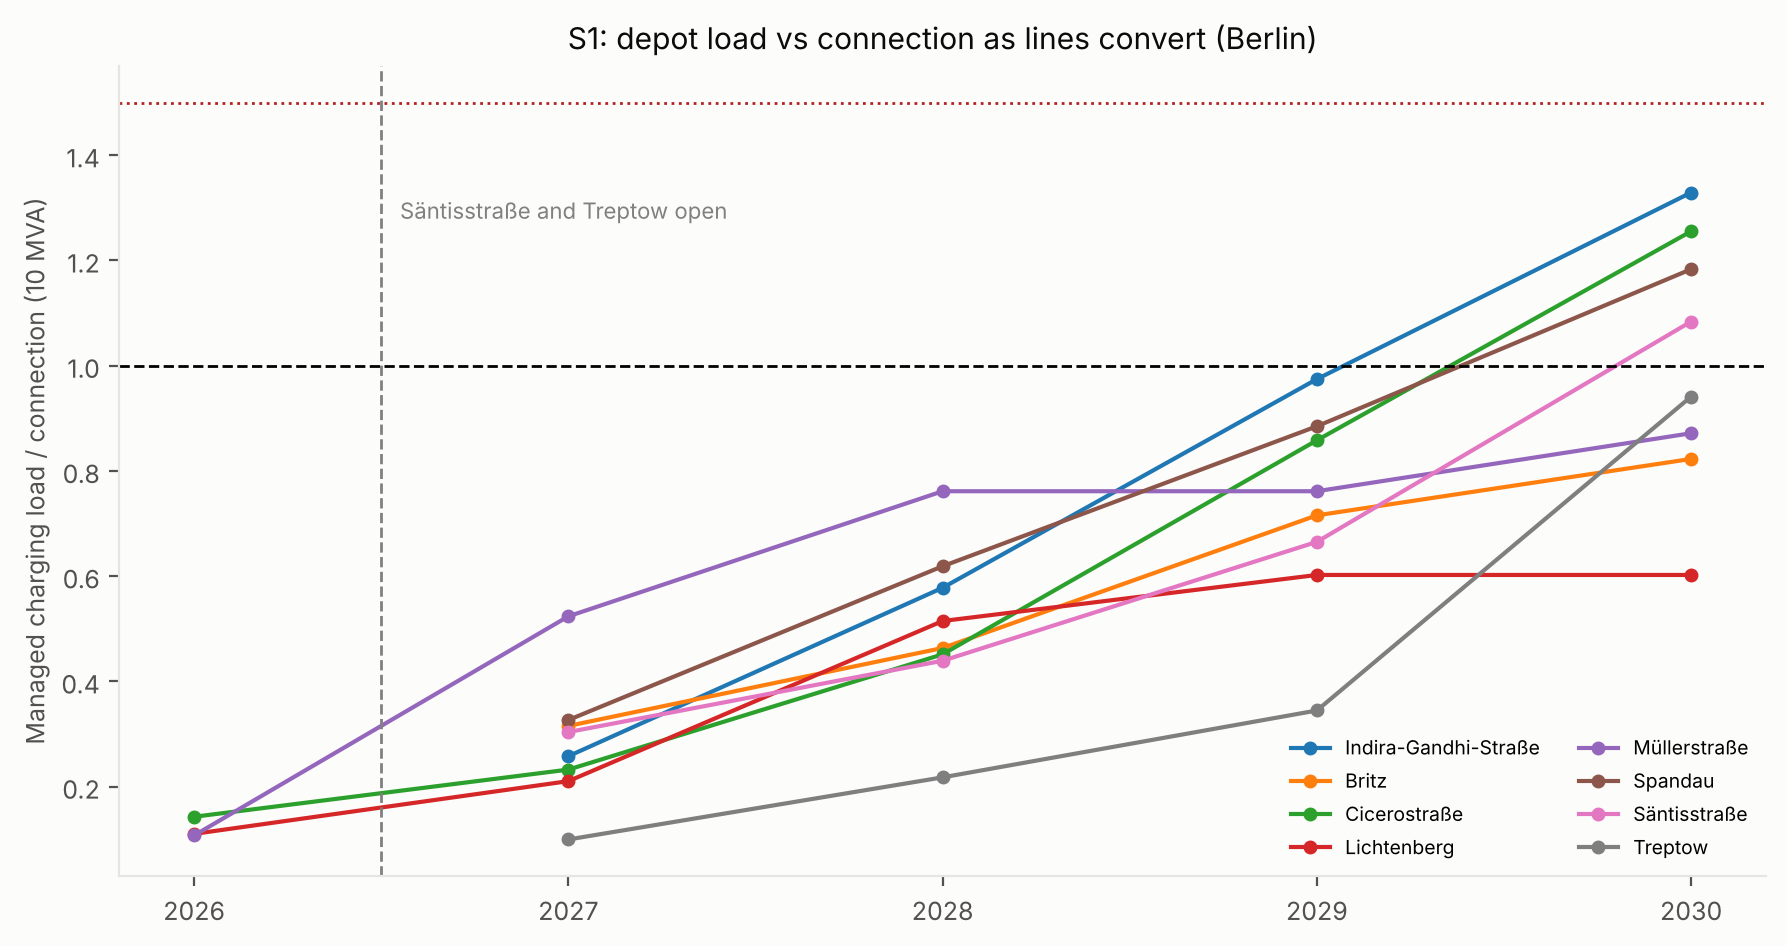

In [16]:
import matplotlib.pyplot as plt
C1, C2, C3 = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e1'
READY_COL = {'Ready': '#2e9e5b', 'Upgrade': '#e8a317', 'Critical': '#c0392b'}
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.titlecolor': INK, 'font.size': 9})

# ---- 10e-1 depot load vs connection by year (S1), allocation B before the new depots open, A after ----
YR = list(range(2026, 2031)); rows = []
for y in YR:
    dep = f2.depot_A if y >= NEW_DEPOTS_OPEN else f2.depot_B
    conv = f2.electrification_year <= y
    n = (f2.peak_buses * f2.energy_kwh_bus_day / 1000)[conv].groupby(dep[conv]).sum().reindex(DEPOTS.index).fillna(0)
    rows.append(n / (FIXED['window_h'] * FIXED['eff']))
load_t = pd.DataFrame(rows, index=YR)
conn_t = pd.Series({d: EVIDENCED_CONN_MW.get(d, CONN_MVA[CONN_SCENARIO]) for d in DEPOTS.index})
ratio_t = load_t / conn_t
print('Managed load of converted lines / connection (low case), by year:'); print(ratio_t.round(2).to_string())
print('\nFirst year above 1.0 x connection:', {d: next((y for y in YR if ratio_t.loc[y, d] > 1), None) for d in ratio_t.columns})
print('First year above 1.5 x connection:', {d: next((y for y in YR if ratio_t.loc[y, d] > 1.5), None) for d in ratio_t.columns})
fig, ax = plt.subplots(figsize=(9, 4.8))
for d in ratio_t.columns:
    ax.plot(YR, ratio_t[d].where(load_t[d] > 0), marker='o', ms=4, label=d)
ax.axvline(NEW_DEPOTS_OPEN - 0.5, color='grey', ls='--', lw=1); ax.text(NEW_DEPOTS_OPEN - 0.45, ax.get_ylim()[1] * 0.92, 'Säntisstraße and Treptow open', fontsize=8, color='grey')
ax.axhline(1.0, color='black', lw=1, ls='--'); ax.axhline(1.5, color='firebrick', lw=1, ls=':')
ax.set_xticks(YR); ax.set_ylabel('Managed charging load / connection (10 MVA)'); ax.set_title('S1: depot load vs connection as lines convert (Berlin)')
ax.legend(frameon=False, fontsize=7, ncol=2); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_depot_load_timeline.png', dpi=200); plt.show()

                      buses_assigned  night_energy_mwh  peak_mw_managed  connection_mw_estimate  managed_to_connection readiness_status  gap_mw_to_ready_low  gap_mw_to_ready_high  managed_kw_per_bus
depot_name                                                                                                                                                                                            
Indira-Gandhi-Straße             319             83.73            13.29                    10.0                   1.33          Upgrade                 3.29                  3.29               41.66
Britz                            133             51.83             8.23                    10.0                   0.82            Ready                 0.00                  0.00               61.85
Cicerostraße                     200             79.09            12.55                    10.0                   1.26          Upgrade                 2.55                  0.00               62.77
Licht

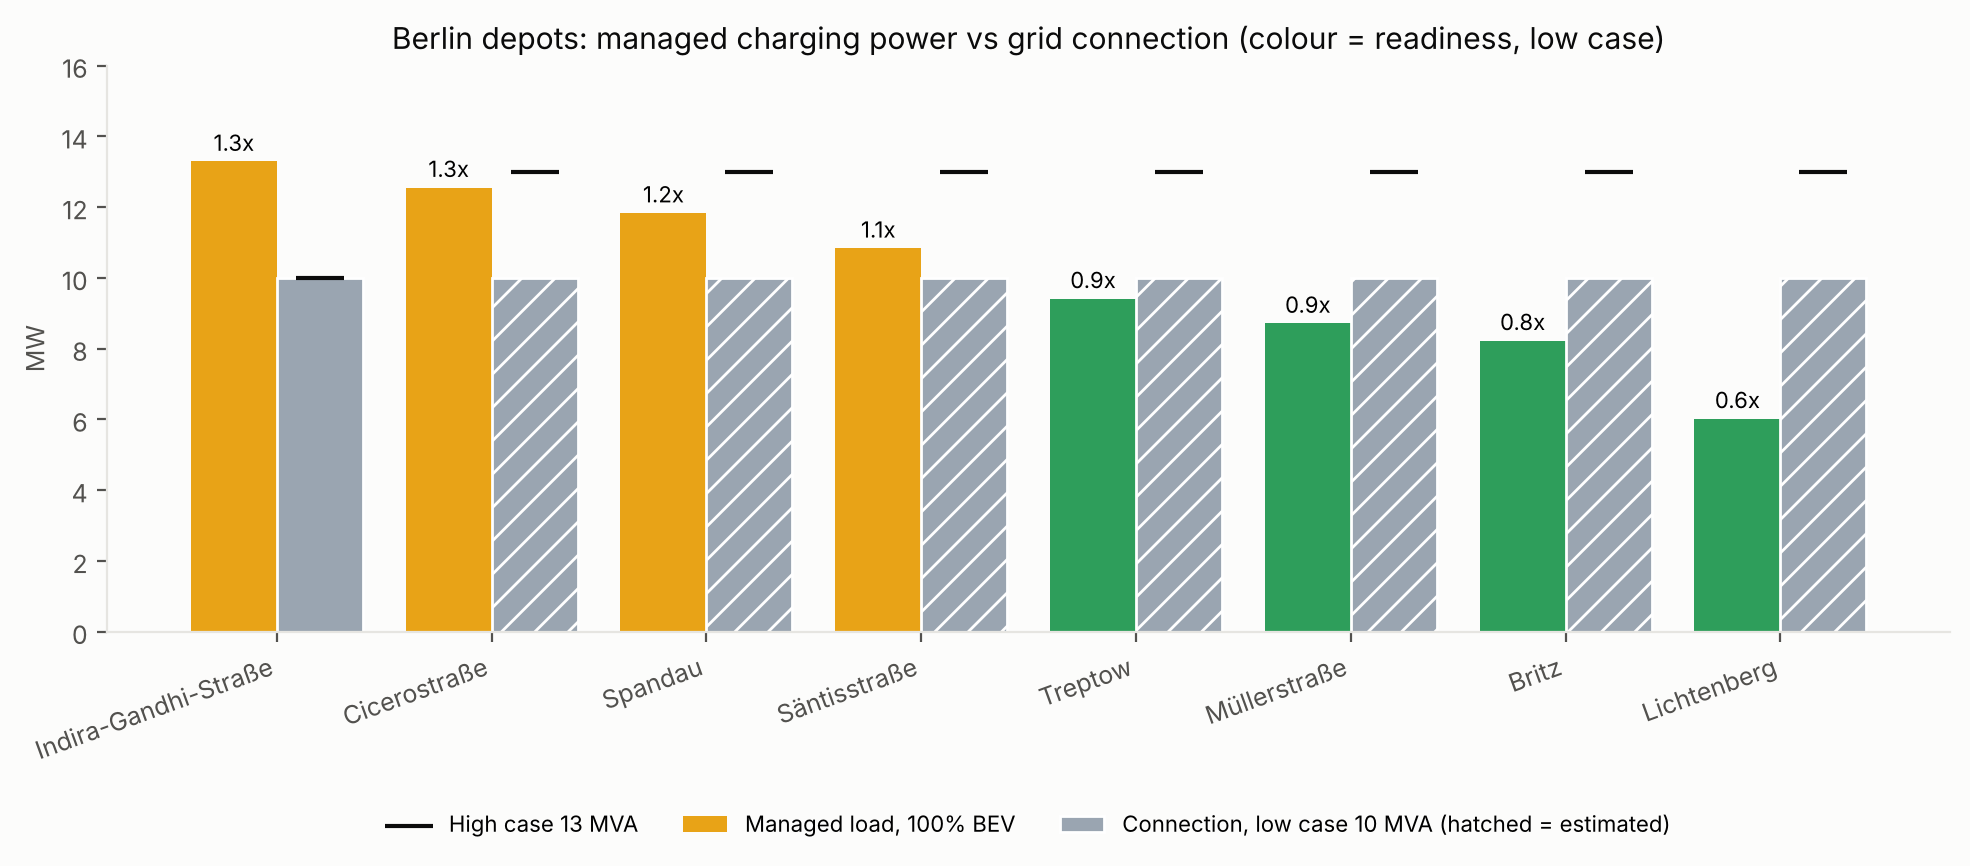

In [17]:
# ---- 10e-2 grid diagnostic per depot (100% BEV, case A), low and high connection ----
d = f3.copy()
d['managed_kw_per_bus'] = d.peak_mw_managed * 1000 / d.buses_assigned
d['gap_mw_to_ready_low'] = (d.peak_mw_managed - d.connection_mw_estimate).clip(lower=0)
d['gap_mw_to_ready_high'] = (d.peak_mw_managed - [EVIDENCED_CONN_MW.get(x, CONN_MVA['high']) for x in d.index]).clip(lower=0)
print(d[['buses_assigned', 'night_energy_mwh', 'peak_mw_managed', 'connection_mw_estimate', 'managed_to_connection', 'readiness_status',
         'gap_mw_to_ready_low', 'gap_mw_to_ready_high', 'managed_kw_per_bus']].round(2).to_string())
print(f'\nNetwork: managed {d.peak_mw_managed.sum():.1f} MW | connections {d.connection_mw_estimate.sum():.0f} MW (low) | '
      f'extra MW for every depot to be Ready: {d.gap_mw_to_ready_low.sum():.1f} (low) / {d.gap_mw_to_ready_high.sum():.1f} (high)')
print(f'Unmanaged (every bus at 100 kW at once): {d.peak_mw_unmanaged.sum():.0f} MW -> managed charging cuts the peak by {100*(1-d.peak_mw_managed.sum()/d.peak_mw_unmanaged.sum()):.0f}%')
win = pd.DataFrame({f'{h} h': d.night_energy_mwh / (h * FIXED['eff']) for h in (5, 6, 7, 8)})
print('\nSupplementary: managed MW for other charging windows:'); print(win.round(1).to_string())
print('Supplementary: with the measured charger efficiency of 85.9%% (federal evaluation p. 211) the network needs %.1f MW instead of %.1f MW.'
      % (d.night_energy_mwh.sum() / (7 * 0.859), d.peak_mw_managed.sum()))

dd = d.sort_values('peak_mw_managed', ascending=False); p = np.arange(len(dd))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(p - 0.2, dd.peak_mw_managed, 0.4, color=[READY_COL[s] for s in dd.readiness_status], label='Managed load, 100% BEV')
ax.bar(p + 0.2, dd.connection_mw_estimate, 0.4, color='#9aa5b1', hatch=['' if e == 'Evidenced' else '//' for e in dd.connection_evidence], edgecolor='white', label='Connection, low case 10 MVA (hatched = estimated)')
ax.scatter(p + 0.2, [EVIDENCED_CONN_MW.get(x, CONN_MVA['high']) for x in dd.index], marker='_', s=300, color=INK, label='High case 13 MVA')
for i, (_, r) in zip(p, dd.iterrows()):
    ax.text(i - 0.2, r.peak_mw_managed + 0.3, f'{r.managed_to_connection:.1f}x', ha='center', fontsize=8)
ax.set_xticks(p); ax.set_xticklabels(dd.index, rotation=20, ha='right'); ax.set_ylabel('MW')
ax.set_title('Berlin depots: managed charging power vs grid connection (colour = readiness, low case)')
ax.set_ylim(0, 16); ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.28)); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_depot_diagnostic.png', dpi=200); plt.show()

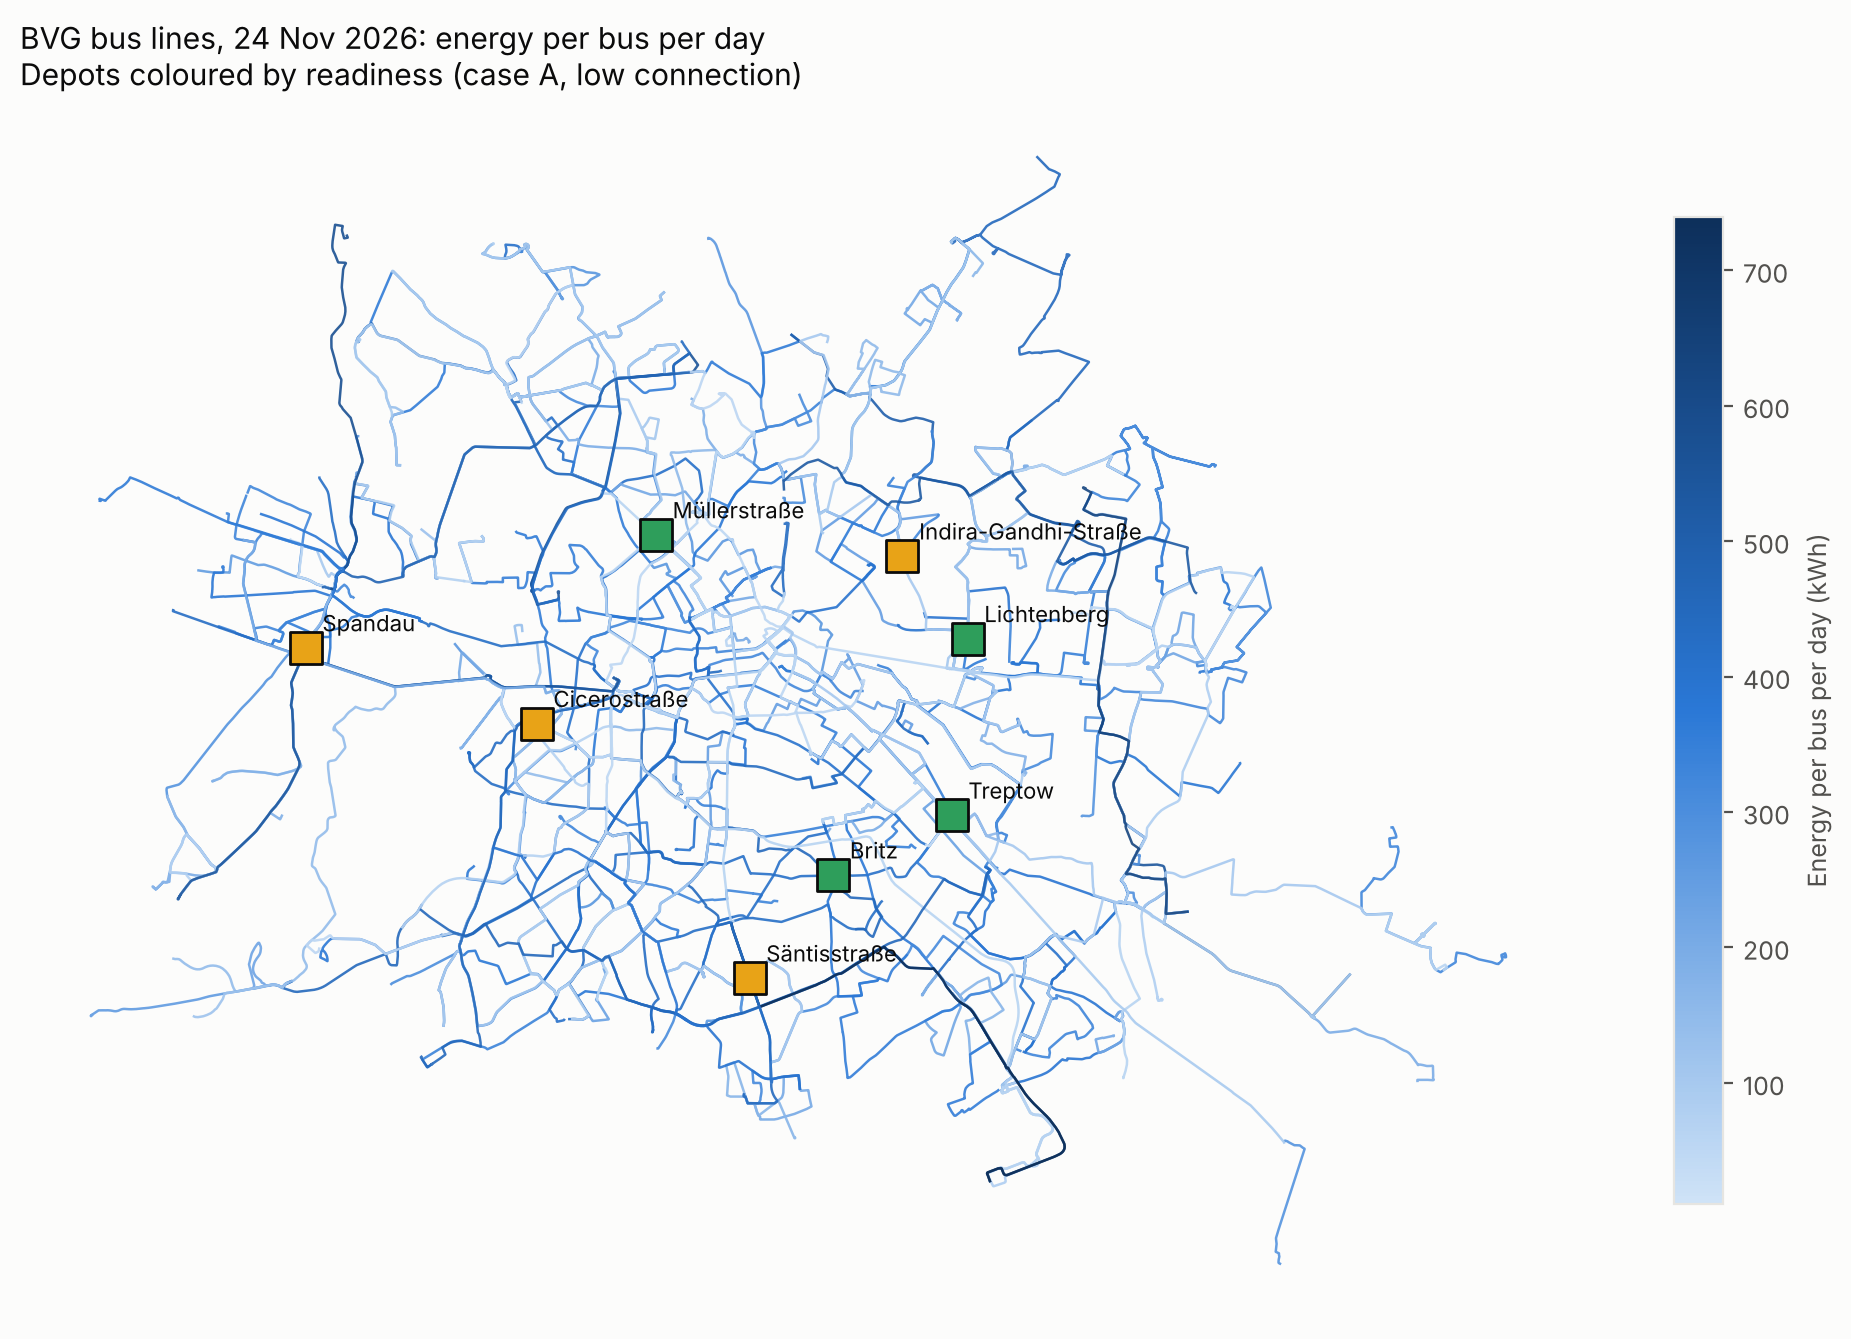

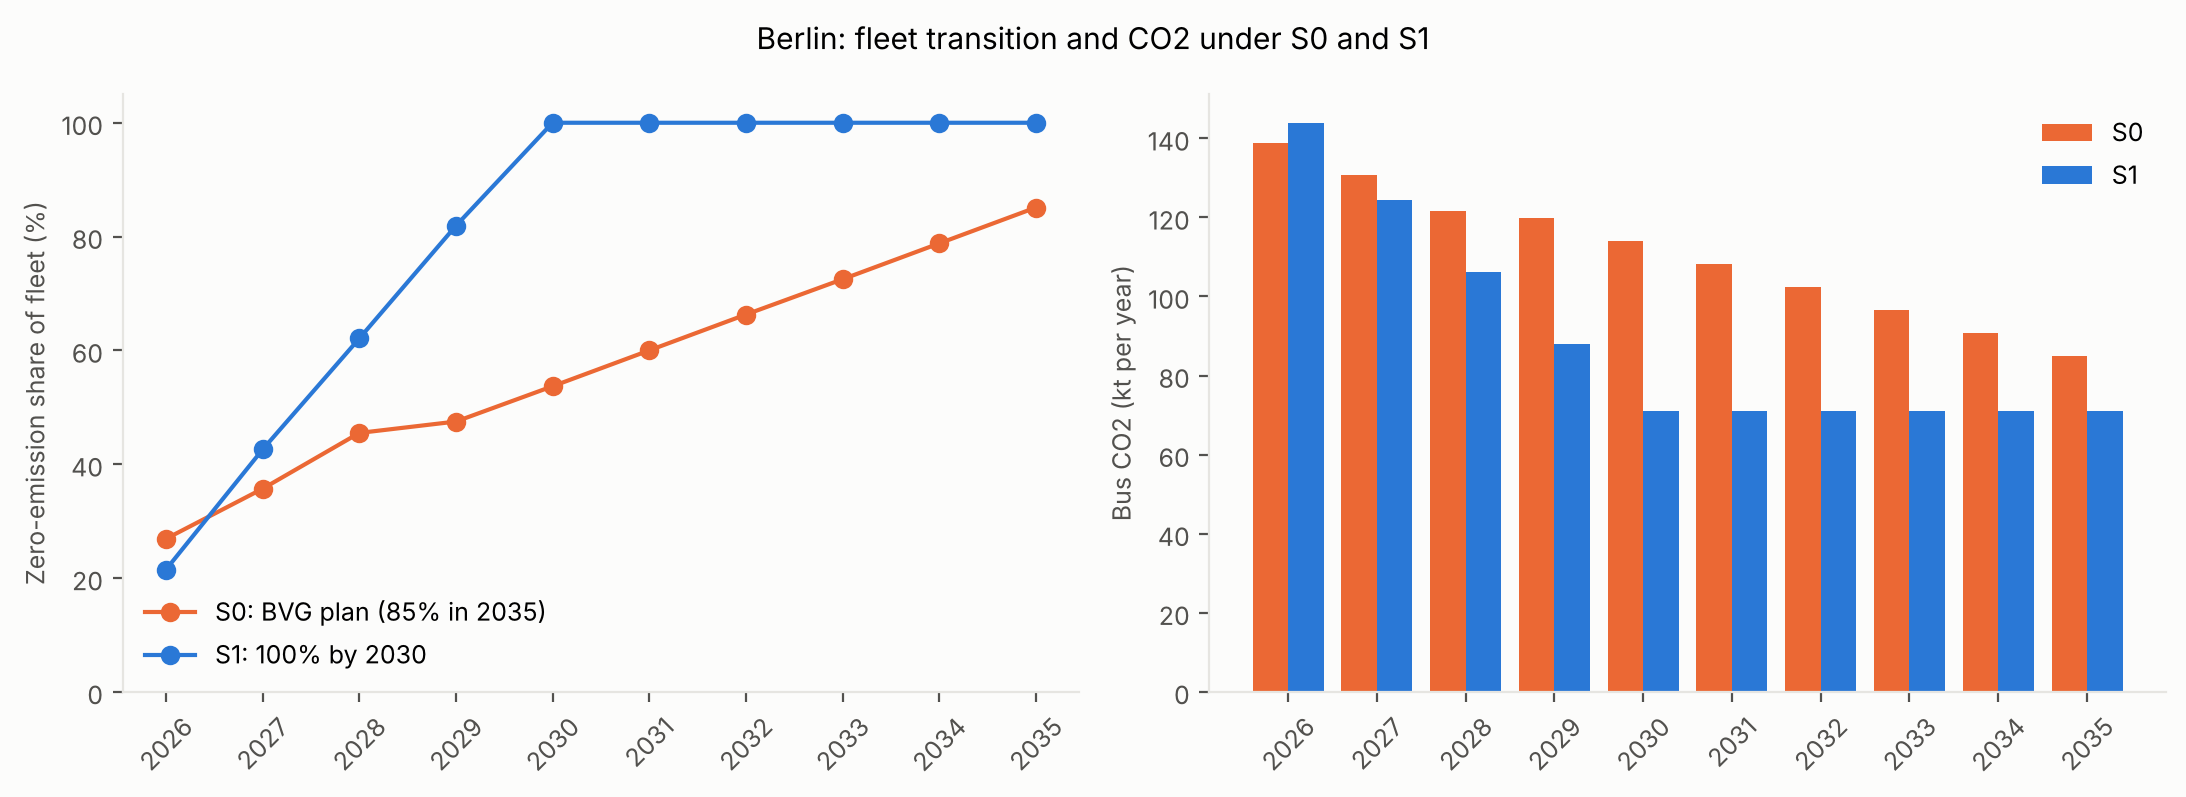

In [18]:
# ---- 10e-3 network map: lines coloured by energy per bus, depots coloured by readiness ----
from matplotlib.colors import LinearSegmentedColormap, Normalize
rep = tt.groupby('route_short_name').shape_id.agg(lambda x: x.value_counts().index[0])
geo = sh[sh.shape_id.isin(set(rep))]
cmap = LinearSegmentedColormap.from_list('e', ['#cfe3f7', C1, '#0d2f5a']); norm = Normalize(f2.energy_kwh_bus_day.min(), f2.energy_kwh_bus_day.max())
e_by_line = f2.set_index('line_id').energy_kwh_bus_day
fig, ax = plt.subplots(figsize=(10, 8.5))
for line, sid in rep.items():
    g = geo[geo.shape_id == sid]
    ax.plot(g.lon, g.lat, color=cmap(norm(e_by_line[line])), lw=0.9, alpha=0.9)
for name, r in DEPOTS.iterrows():
    status = f3.readiness_status.get(name, 'Ready')
    ax.scatter(r.longitude, r.latitude, s=140, color=READY_COL[status], edgecolor=INK, zorder=5, marker='s')
    ax.annotate(name, (r.longitude, r.latitude), xytext=(6, 6), textcoords='offset points', fontsize=8, color=INK)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); fig.colorbar(sm, ax=ax, shrink=0.6, label='Energy per bus per day (kWh)')
ax.set_aspect(1 / np.cos(np.radians(52.5))); ax.set_axis_off()
ax.set_title('BVG bus lines, 24 Nov 2026: energy per bus per day\nDepots coloured by readiness (case A, low connection)', loc='left')
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_network_energy_map.png', dpi=200); plt.show()

# ---- 10e-4 fleet transition: S0 (BVG plan) vs S1 (100% by 2030) ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(YEARS, t0.ze_share_pct, marker='o', color=C2, label='S0: BVG plan (85% in 2035)'); ax[0].plot(YEARS, t1.ze_share_pct, marker='o', color=C1, label='S1: 100% by 2030')
ax[0].set_ylabel('Zero-emission share of fleet (%)'); ax[0].set_ylim(0, 105); ax[0].legend(frameon=False)
ax[1].bar(np.array(YEARS) - 0.2, t0.co2_t / 1000, 0.4, color=C2, label='S0'); ax[1].bar(np.array(YEARS) + 0.2, t1.co2_t / 1000, 0.4, color=C1, label='S1')
ax[1].set_ylabel('Bus CO2 (kt per year)'); ax[1].legend(frameon=False)
for a in ax: a.spines[['top', 'right']].set_visible(False); a.set_xticks(YEARS); a.tick_params(axis='x', rotation=45)
fig.suptitle('Berlin: fleet transition and CO2 under S0 and S1'); fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_fleet_transition.png', dpi=200); plt.show()

## 10f. File 1 row for Berlin and benchmark against Madrid
Same fields as the Helsinki row (`Helsinki/outputs/helsinki_file1.csv`). `energy_full_bev_mwh_day` follows the benchmark convention (daily bus-km x 1.30 kWh/km). The benchmark table puts Berlin next to Madrid's saved outputs.

In [19]:
SRC = ' | '.join(['https://vbb.de/vbb-services/api-open-data/datensaetze/ (VBB GTFS, downloaded 2026-11-18)',
                  'https://www.bvg.de/dam/jcr:b7825abf-7399-4ead-bdd1-5d315d94808a/BVG-in-Zahlen-2025.pdf',
                  'https://www.bvg.de/dam/jcr:99b45b88-6814-4f3e-959d-6ef440adf229/BVG-Nachhaltigkeitsbericht-2025.pdf',
                  'https://www.umweltbundesamt.de/themen/co2-emissionen-pro-kilowattstunde-strom-2025-nur'])
file1 = pd.DataFrame([{
    'city': 'Berlin', 'operator': 'BVG Berliner Verkehrsbetriebe (bus network, incl. subcontracted lines)',
    'reference_date': REFERENCE_DATE, 'n_bus_lines': len(f2), 'daily_bus_km': round(f2.daily_km.sum(), 1),
    'fleet_total': FLEET_TOTAL, 'ze_fleet': N_BEV + N_H2, 'ze_share_pct': round(100 * (N_BEV + N_H2) / FLEET_TOTAL, 1),
    'fleet_data_year': 2025, 'ze_target_year': 2035,
    'charging_model': 'Depot (plug-in CCS and pantograph) + terminus opportunity charging (line 200; STELLA up to 20 terminals by 2027)',
    'energy_full_bev_mwh_day': round(f2.daily_km.sum() * 1.30 / 1000, 1), 'grid_co2_g_kwh': 344, 'source_urls': SRC}])
file1.to_csv(OUT_DIR / 'berlin_file1.csv', index=False); print(file1.T.to_string())

mad = Path('../Madrid/outputs')
if (mad / 'File_2.csv').exists():
    M2, M3 = pd.read_csv(mad / 'File_2.csv', dtype={'line_id': str}), pd.read_csv(mad / 'File_3.csv')
    def summary(F2_, F3_, fleet, ze):
        return {'Bus lines (weekday)': len(F2_), 'Daily bus-km': round(F2_.daily_km.sum()), 'Peak buses (sum of lines)': int(F2_.peak_buses.sum()),
                'km per peak bus per day (median)': round(F2_.km_per_bus_day.median(), 1), 'Articulated share of peak buses (%)': round(100 * F2_.loc[F2_.bus_type == 'Articulated', 'peak_buses'].sum() / F2_.peak_buses.sum(), 1),
                'Lines needing opportunity charging': int((F2_.charging_strategy != 'Depot').sum()), 'Depots': len(F3_),
                '100% BEV night energy (MWh/day)': round(F3_.night_energy_mwh.sum(), 1), 'Managed charging power (MW)': round(F3_.peak_mw_managed.sum(), 1),
                'Depots Ready / Upgrade / Critical': '/'.join(str(int((F3_.readiness_status == s).sum())) for s in ['Ready', 'Upgrade', 'Critical']),
                'Fleet total': fleet, 'Zero-emission share of fleet (%)': round(100 * ze / fleet, 1)}
    bench = pd.DataFrame({'Madrid (EMT)': summary(M2, M3, 2210, 462), 'Berlin (BVG)': summary(F2, F3, FLEET_TOTAL, N_BEV + N_H2)})
    bench.to_csv(OUT_DIR / 'benchmark_berlin_madrid.csv'); print(bench.to_string())
else:
    print('Madrid outputs not found next to this folder: benchmark skipped')

                                                                                                                                                                                                                                                                                                                                                                                                        0
city                                                                                                                                                                                                                                                                                                                                                                                               Berlin
operator                                                                                                                                                                                                            

## 10g. Benchmark must-haves (team checklist, same for all 5 cities)
One table answers the team checklist for Berlin; each row has its value, the source URL and a label (V verified, D derived from GTFS/model, P proxy, A assumption, **GAP** not published). Saved as `outputs/berlin_must_haves.csv`; depot rows as `outputs/berlin_depots_benchmark.csv`. Four figures support the 5-city comparison: depot and line map, fleet mix by year, e-buses added per year, and the daily vehicle curve with the midday dip.

Source tiers follow the Doc: official papers and BVG first; press (electrive, nd-aktuell) with date; enthusiast sites only as cross-checks.

In [20]:
U = {
 'ZAHLEN25': 'https://www.bvg.de/dam/jcr:b7825abf-7399-4ead-bdd1-5d315d94808a/BVG-in-Zahlen-2025.pdf',
 'ZAHLEN24': 'https://www.bvg.de/dam/jcr:27ceb5b8-a738-400e-b288-0044d523d050/2025-05-05-bvg-in-zahlen-2024.pdf',
 'ZS22': 'https://www.bvg.de/dam/jcr:f7efd356-6b51-4f34-bbe0-1261c76fdb79/BVG_Zahlenspiegel_2022.pdf',
 'ZS23': 'https://www.bvg.de/dam/jcr:2f66007e-6743-40a7-a1d4-51707f282faa/BVG-Zahlenspiegel-2023.pdf',
 'SUST25': 'https://www.bvg.de/dam/jcr:99b45b88-6814-4f3e-959d-6ef440adf229/BVG-Nachhaltigkeitsbericht-2025.pdf',
 'H190560': 'https://www.parlament-berlin.de/adosservice/19/Haupt/vorgang/h19-0560-v.pdf',
 'H192626': 'https://www.parlament-berlin.de/adosservice/19/Haupt/vorgang/h19-2626-v.pdf',
 'H183441': 'https://www.parlament-berlin.de/adosservice/18/Haupt/vorgang/h18-3441.A-v.pdf',
 'S22944': 'https://pardok.parlament-berlin.de/starweb/adis/citat/VT/19/SchrAnfr/S19-22944.pdf',
 'S24976': 'https://pardok.parlament-berlin.de/starweb/adis/citat/VT/19/SchrAnfr/S19-24976.pdf',
 'NOW': 'https://www.now-gmbh.de/wp-content/uploads/2020/09/now_broschuere_zero-emission-busse.pdf',
 'FED': 'https://www.pwc.de/de/branchen-und-markte/oeffentlicher-sektor/begleituntersuchung-zur-foerderung-von-elektrobussen-im-oepnv.pdf',
 'EMOB': 'https://www.bvg.de/de/unternehmen/nachhaltige-mobilitaet/flotte/e-mobilitaet',
 'SAENTIS': 'https://www.bvg.de/de/unternehmen/herzensprojekte/betriebshof-saentisstrasse',
 'SAENTIS_PDF': 'https://www.bvg.de/dam/jcr:64b42d07-372c-4018-b6e7-c4d439b9f267/Projektvorstellung%20E-Busbetriebshof%20S%C3%A4ntisstra%C3%9Fe.pdf',
 'SWECO': 'https://www.sweco-gmbh.de/showroom/bvg-betriebshof/',
 'EL_SAENTIS': 'https://www.electrive.net/2026/03/18/bvg-zelebriert-richtfest-am-elektrobus-depot-in-marienfelde/',
 'EL_TREPTOW': 'https://www.electrive.net/2025/12/11/bvg-feiert-richtfest-am-elektrobus-betriebshof-treptow/',
 'PM_TREPTOW': 'https://www.bvg.de/de/unternehmen/medienportal/pressemitteilungen/2025-03-13-neuer-betriebshof',
 'PM_STELLA26': 'https://www.bvg.de/de/unternehmen/medienportal/pressemitteilungen/20260626-pm-volle-energie-fuer-e-busse',
 'PM_STELLA25': 'https://www.bvg.de/de/unternehmen/medienportal/pressemitteilungen/2025-10-06-pm-bvg-baut-schnellladestationen',
 'PM_M2G': 'https://www.bvg.de/de/unternehmen/medienportal/pressemitteilungen/elektrobusse-intelligent-laden-forschungscampus-mobility2grid-nimmt-innovative-ladestation-in-betrieb',
 'DURCH': 'https://xn--durchstarterset-elektromobilitt-kwc.de/praxisbeispiele/e-metrobus-gelegenheitsladen-fuer-die-buslinie-200-der-bvg-2/',
 'EL_ORDER': 'https://www.electrive.net/2025/06/30/bvg-bestellen-270-weitere-e-gelenkbusse-bei-solaris/',
 'CAF': 'https://www.cafmobility.com/en/press-room/bvg-confirms-new-order-solaris-270-electric-articulated-buses-germany/',
 'PM_2019': 'https://www.bvg.de/de/unternehmen/medienportal/pressemitteilungen/weitere-e-busse-fuer-die-bvg',
 'ND_SAENTIS': 'https://www.nd-aktuell.de/artikel/1193192.e-mobilitaet-busflotte-der-bvg-elektro-anschluss-fuer-marienfelde.html',
 'ND_TREPTOW': 'https://www.nd-aktuell.de/artikel/1196189.elektromobilitaet-bvg-maximal-prozent-e-busse-bis.html',
 'OMNI_CUT': 'https://omnibus.news/bvg-e-bus-budget-gekuerzt',
 'SNB': 'https://www.stromnetz.berlin/anschliessen/anschluss-mittel-hochspannung/repartierung/',
 'GREEN': 'https://unternehmen.bvg.de/wp-content/uploads/2024/07/20240708_PM_Vier-Mal-BVG-Sonne.pdf',
 'GTFS': 'https://vbb.de/vbb-services/api-open-data/datensaetze/',
 'LINIENCHRONIK': 'https://www.berliner-linienchronik.de/fahrzeuge-bvg.html',
}

# ---- derived numbers (D) ----
vc_ = vc.set_index('minute').vehicles
noon, vpeak = float(vc_.loc[12 * 60]), float(vc_.max())
am_peak = float(vc_.loc[6 * 60:9 * 60].max())
midday_dip_pct = round(100 * noon / am_peak, 1)
min_10_15 = float(vc_.loc[10 * 60:15 * 60].min())
daily_km = float(f2.daily_km.sum()); net_peak = int(net[LAYOVER_MIN])
km_per_bus_network = daily_km / net_peak
print(f'Vehicles in service: AM peak {am_peak:.0f}, noon {noon:.0f} -> {midday_dip_pct}% still out at 12:00 ({100 - midday_dip_pct:.1f}% back at depots or terminals); min 10-15 h: {min_10_15:.0f}')
print(f'km per bus per day: median line {f2.km_per_bus_day.median():.0f}, P90 {f2.km_per_bus_day.quantile(.9):.0f}, network {km_per_bus_network:.0f} (daily km / network peak)')
over_300 = int((f2.km_per_bus_day > 300).sum())
print(f'Lines whose buses run > 300 km per day (brief range): {over_300}')

# first e-bus lines (2019-2022, Senate h19-0560 / electrive): why these lines?
FIRST = ['142', '147', '155', '194', '250', '259', '294', '300', '347', '200']
igs = DEPOTS.loc['Indira-Gandhi-Straße']
def km_to(lat, lon, d): return haversine(lat, lon, d.latitude, d.longitude)
fl = f2[f2.line_id.isin(FIRST)].copy()
fl['km_to_IGS'] = km_to(fl.lat, fl.lon, igs)
rest = f2[~f2.line_id.isin(FIRST)]
print('\nFirst electric lines vs the rest of the network (D):')
print(pd.DataFrame({'first e-lines (median)': [fl.km_per_bus_day.median(), fl.km_to_IGS.median(), fl.peak_buses.median()],
                    'other lines (median)': [rest.km_per_bus_day.median(), km_to(rest.lat, rest.lon, igs).median(), rest.peak_buses.median()]},
                   index=['km per bus per day', 'km from line centre to IGS depot', 'peak buses']).round(1).to_string())

Vehicles in service: AM peak 1165, noon 955 -> 82.0% still out at 12:00 (18.0% back at depots or terminals); min 10-15 h: 939
km per bus per day: median line 177, P90 246, network 250 (daily km / network peak)
Lines whose buses run > 300 km per day (brief range): 6

First electric lines vs the rest of the network (D):
                                  first e-lines (median)  other lines (median)
km per bus per day                                 181.9                 176.6
km from line centre to IGS depot                     5.3                  12.2
peak buses                                           6.0                   6.0


In [21]:
# ---- depot benchmark table: capacity, chargers, power, connection, kVA per bus ----
dep = pd.DataFrame([
 # depot, buses today (enthusiast), e-bus places, charging points, charger kW / type, connection MW (evidence)
 ['Indira-Gandhi-Straße', 428, 280, 133, '30x100 kW + 103x150 kW CCS plug; 1x300 kW pantograph mast', 10.0, 'V (10 MW, 2020)', U['S22944'] + ' | ' + U['H190560'] + ' | ' + U['NOW']],
 ['Britz', 258, 30, 28, 'plug (kW not published)', np.nan, 'GAP', U['H190560'] + ' | ' + U['S22944']],
 ['Cicerostraße', 204, 30, 28, 'plug (kW not published)', np.nan, 'GAP', U['H190560'] + ' | ' + U['S22944']],
 ['Lichtenberg', 198, 0, 0, 'none yet (conversion 2033)', np.nan, 'GAP', U['S22944']],
 ['Müllerstraße', 231, 0, 0, 'none yet (conversion 2035)', np.nan, 'GAP', U['S22944']],
 ['Spandau', 243, 0, 0, 'none yet (conversion 2030)', np.nan, 'GAP', U['S22944']],
 ['Säntisstraße (2027)', 0, 220, 218, '209 pantograph up to 150 kW + 9 HPC up to 450 kW', np.nan, 'GAP (10 kV station built)', U['SAENTIS'] + ' | ' + U['EL_SAENTIS'] + ' | ' + U['SWECO']],
 ['Treptow (2027)', 0, 200, np.nan, 'overhead charging bridges (pantograph); count not published', np.nan, 'GAP (applied 2026)', U['PM_TREPTOW'] + ' | ' + U['EL_TREPTOW'] + ' | ' + U['H192626']],
], columns=['depot', 'buses_today_est', 'ebus_places', 'charging_points', 'charger_power_type', 'connection_mw_published', 'connection_label', 'sources'])
key = dep.depot.str.replace(r' \(2027\)', '', regex=True)
dep['latitude'] = key.map(DEPOTS.latitude).values; dep['longitude'] = key.map(DEPOTS.longitude).values
dep['peak_buses_model_caseA'] = key.map(f3.buses_assigned).values
dep['chargers_per_ebus'] = (dep.charging_points / dep.ebus_places.replace(0, np.nan)).round(2)
dep['kva_per_ebus_published'] = (1000 * dep.connection_mw_published / dep.ebus_places.replace(0, np.nan)).round(0)
dep['kva_per_bus_model_low'] = (1000 * key.map(f3.connection_mw_estimate) / key.map(f3.buses_assigned)).round(0).values
dep['kw_per_bus_needed_managed'] = (1000 * key.map(f3.peak_mw_managed) / key.map(f3.buses_assigned)).round(0).values
dep.to_csv(OUT_DIR / 'berlin_depots_benchmark.csv', index=False)
print(dep.drop(columns=['sources', 'latitude', 'longitude']).to_string(index=False))
print('\nbuses_today_est: berliner-linienchronik (enthusiast, cross-check only; sum 1,562 vs official 1,532).')
ok('Depot table has the 8 model depots', dep.latitude.notna().all() and len(dep) == 8)

               depot  buses_today_est  ebus_places  charging_points                                          charger_power_type  connection_mw_published          connection_label  peak_buses_model_caseA  chargers_per_ebus  kva_per_ebus_published  kva_per_bus_model_low  kw_per_bus_needed_managed
Indira-Gandhi-Straße              428          280            133.0   30x100 kW + 103x150 kW CCS plug; 1x300 kW pantograph mast                     10.0           V (10 MW, 2020)                     319               0.48                    36.0                   31.0                       42.0
               Britz              258           30             28.0                                     plug (kW not published)                      NaN                       GAP                     133               0.93                     NaN                   75.0                       62.0
        Cicerostraße              204           30             28.0                                     plug (kW

In [22]:
# ---- the checklist itself ----
row = lambda item, value, label, src, note='': dict(item=item, berlin=value, label=label, source=src, note=note)
mh = pd.DataFrame([
 row('Depots: number, names', '6 today (Indira-Gandhi-Str., Britz, Cicerostr., Lichtenberg, Müllerstr., Spandau) + 2 e-only from 2027 (Säntisstr., Treptow); Rummelsburger Landstr. 2028', 'V', U['S22944'] + ' | ' + U['EL_SAENTIS']),
 row('Depots: locations', 'GTFS depot stops (4 exact, 4 nearest-stop proxies); see map', 'D/P', U['GTFS']),
 row('Buses per depot (peak / capacity)', 'Today ~198-428 buses per depot; e-bus places: IGS ~280, Säntisstr. ~220, Treptow ~200, Britz ~30, Cicerostr. ~30; model case A peak 115-319', 'V/P', U['S22944'] + ' | ' + U['LINIENCHRONIK'], 'Overload risk: IGS carries most e-buses until the new depots open (same pattern as La Elipa in Madrid)'),
 row('Grid connection per depot (MVA/MW)', 'Only IGS published: 10 MW (2020). Others: 10 MVA low / 13 MVA high per depot (Senate grid-allocation report)', 'V/P', U['NOW'] + ' | ' + U['H192626'], 'Berlin-wide: Stromnetz Berlin shared 365 MVA among 37 requests vs ~2,300 MVA asked (2025)'),
 row('kVA per e-bus', 'IGS: 10 MW / ~280 e-bus places = ~36 kVA per bus (published). Model need with managed charging: 41-63 kW per bus by depot; 10 MVA gives 43-87 kVA per allocated bus', 'D', U['NOW'] + ' | ' + U['S22944']),
 row('Charging points per depot, power, type', 'IGS 133 plug CCS (100-150 kW) + 1 pantograph 300 kW; Britz 28; Cicerostr. 28; Säntisstr. 209 pantograph ≤150 kW + 9 HPC ≤450 kW; Treptow charging bridges (count n/p)', 'V', U['H190560'] + ' | ' + U['NOW'] + ' | ' + U['EL_SAENTIS'] + ' | ' + U['SWECO']),
 row('Chargers per bus', 'IGS ~0.5 (133/280); Britz, Cicerostr. ~0.93 (28/30); Säntisstr. ~0.95-1.0 (209-218/220)', 'D', U['H190560'] + ' | ' + U['SAENTIS']),
 row('Terminal / opportunity charging', 'Line 200 since 2020: 2 terminals (Hertzallee, Michelangelostr.) x 2 HPC up to 450 kW, inverted pantograph. STELLA: up to 20 terminal chargers by end 2027 (6 under construction; Marzahn in trial since Jun 2026). Model flags 17 lines for opportunity charging', 'V/D', U['NOW'] + ' | ' + U['DURCH'] + ' | ' + U['PM_STELLA26']),
 row('Coping with a short grid', 'Load and charging management (LLMS) linking depot management and chargers in real time; PV on Säntisstr. roofs; 100% green electricity contract; Mobility2Grid research station (EUREF) for smart charging. Depot battery storage: not published', 'V / GAP', U['EMOB'] + ' | ' + U['SAENTIS_PDF'] + ' | ' + U['GREEN'] + ' | ' + U['PM_M2G']),
 row('Peak buses in service', f'{net_peak:,} network peak (GTFS, 5-min layover); {int(f2.peak_buses.sum()):,} sum of line peaks; fleet 1,532', 'D', U['GTFS'] + ' | ' + U['ZAHLEN25']),
 row('Daily bus-km (network)', f'{daily_km:,.0f} km on 24 Nov 2026 (GTFS); official 89.7 M vehicle-km per year (2025)', 'D/V', U['GTFS'] + ' | ' + U['ZAHLEN25']),
 row('Km per bus per day', f'median line {f2.km_per_bus_day.median():.0f} km; P90 {f2.km_per_bus_day.quantile(.9):.0f} km; network {km_per_bus_network:.0f} km; {over_300} lines above 300 km', 'D', U['GTFS']),
 row('Energy per day at 100% electric', f'{daily_km * 1.30 / 1000:,.0f} MWh (all km x 1.30 kWh/km); {f3.night_energy_mwh.sum():,.0f} MWh with the brief\'s articulated 1.85 kWh/km', 'D', U['GTFS']),
 row('Midday dip: % of buses out at 12:00', f'{midday_dip_pct}% of the morning peak ({noon:.0f} of {am_peak:.0f})', 'D', U['GTFS'], 'Small dip: Berlin runs a flat daytime timetable, so midday charging is limited'),
 row('Fleet mix (31 Dec 2025)', '1,532: 277 battery-electric (18%), 1,255 diesel (202 solo, 838 articulated/15 m, 199 double-deck, 16 special). No hybrids or H2 reported', 'V', U['ZAHLEN25']),
 row('Fleet mix by year', 'See figure: 2021-2025 from BVG Zahlenspiegel / BVG in Zahlen', 'V', U['ZS22'] + ' | ' + U['ZS23'] + ' | ' + U['ZAHLEN24'] + ' | ' + U['ZAHLEN25']),
 row('E-buses added per year (net)', '2019 +30, 2020 +107, 2021 +1, 2022 +89, 2023 0, 2024 +1, 2025 +49; plan 2026-27 +270, 2028 +150, 2029 +30', 'V', U['H190560'] + ' | ' + U['ZAHLEN24'] + ' | ' + U['ZAHLEN25'] + ' | ' + U['SUST25'], '2024: Senate cut e-bus budget from €33.1M to €8M; 2025: Ebusco frame cracks'),
 row('Cost per e-bus', '12 m: ~€583k (2019, 30 buses €17.5M); articulated: ~€780k (line 200, €13.3M/17); Solaris Urbino 18 order 2025: >€220M/270 = ~€815k', 'V/D', U['FED'] + ' (table 25, p. 303) | ' + U['CAF']),
 row('Cost: depot conversion / new depot', 'Säntisstr. ~€190M (220 buses); Treptow ~€120M excl. land (~200 buses); all 9 depots ~€1.3bn; total electrification 2019-2035 €1.7-2.3bn', 'V', U['ND_SAENTIS'] + ' | ' + U['ND_TREPTOW'] + ' | ' + U['S22944']),
 row('Cost: charging and grid', '2019 batch: €10.7M charging for 30 buses (~€357k/bus); E-Metrobus 200: line charging €55M, depot charging €16M, grid connection €2M', 'V', U['FED'] + ' | ' + U['H183441']),
 row('Funding sources', 'Federal e-bus programmes (BMU/BMWK, evaluated 2018-23); for the 320 articulated: ~50% BVG, ~40% federal, ~10% Land Berlin; €160M federal for BIG 2025; €12.1M federal for STELLA terminal chargers', 'V', U['FED'] + ' | ' + U['S22944'] + ' | ' + U['PM_STELLA26'] + ' | ' + U['PM_STELLA25']),
 row('Which lines went electric first, and why', '2019-22: 142, 147, 155, 194, 250, 259, 294, 300, 347 (from IGS) + 200 (opportunity). Logic: proximity to the first converted depot (median line centre 5 km from IGS vs 12 km for other lines). Not shorter duties: ~180 km per bus per day like the rest, above the 130-150 km of the 2019 batteries, hence the >33% reserve fleet the Senate reported', 'V/D', U['H190560'] + ' | ' + U['NOW']),
 row('Cool to have: buses bought, why, where', 'Solaris Urbino 18 electric (~700 kWh, plug or pantograph): 270 ordered 2025, framework up to 700, to replace diesel articulated on Metro lines; 10 e-double-deckers + 20 e-24 m buses planned 2029. Earlier: Solaris Urbino 12, Mercedes eCitaro, Ebusco 2.2', 'V', U['EL_ORDER'] + ' | ' + U['S22944'] + ' | ' + U['H190560']),
])
mh.to_csv(OUT_DIR / 'berlin_must_haves.csv', index=False)
pd.set_option('display.max_colwidth', 110)
print(mh[['item', 'berlin', 'label']].to_string(index=False))
print('\nRows with a gap:', ', '.join(mh.loc[mh.label.str.contains('GAP'), 'item']))

                                    item                                                                                                                                                                                                                                                                                                                                                  berlin   label
                   Depots: number, names                                                                                                                                                                                               6 today (Indira-Gandhi-Str., Britz, Cicerostr., Lichtenberg, Müllerstr., Spandau) + 2 e-only from 2027 (Säntisstr., Treptow); Rummelsburger Landstr. 2028       V
                       Depots: locations                                                                                                                                                                              

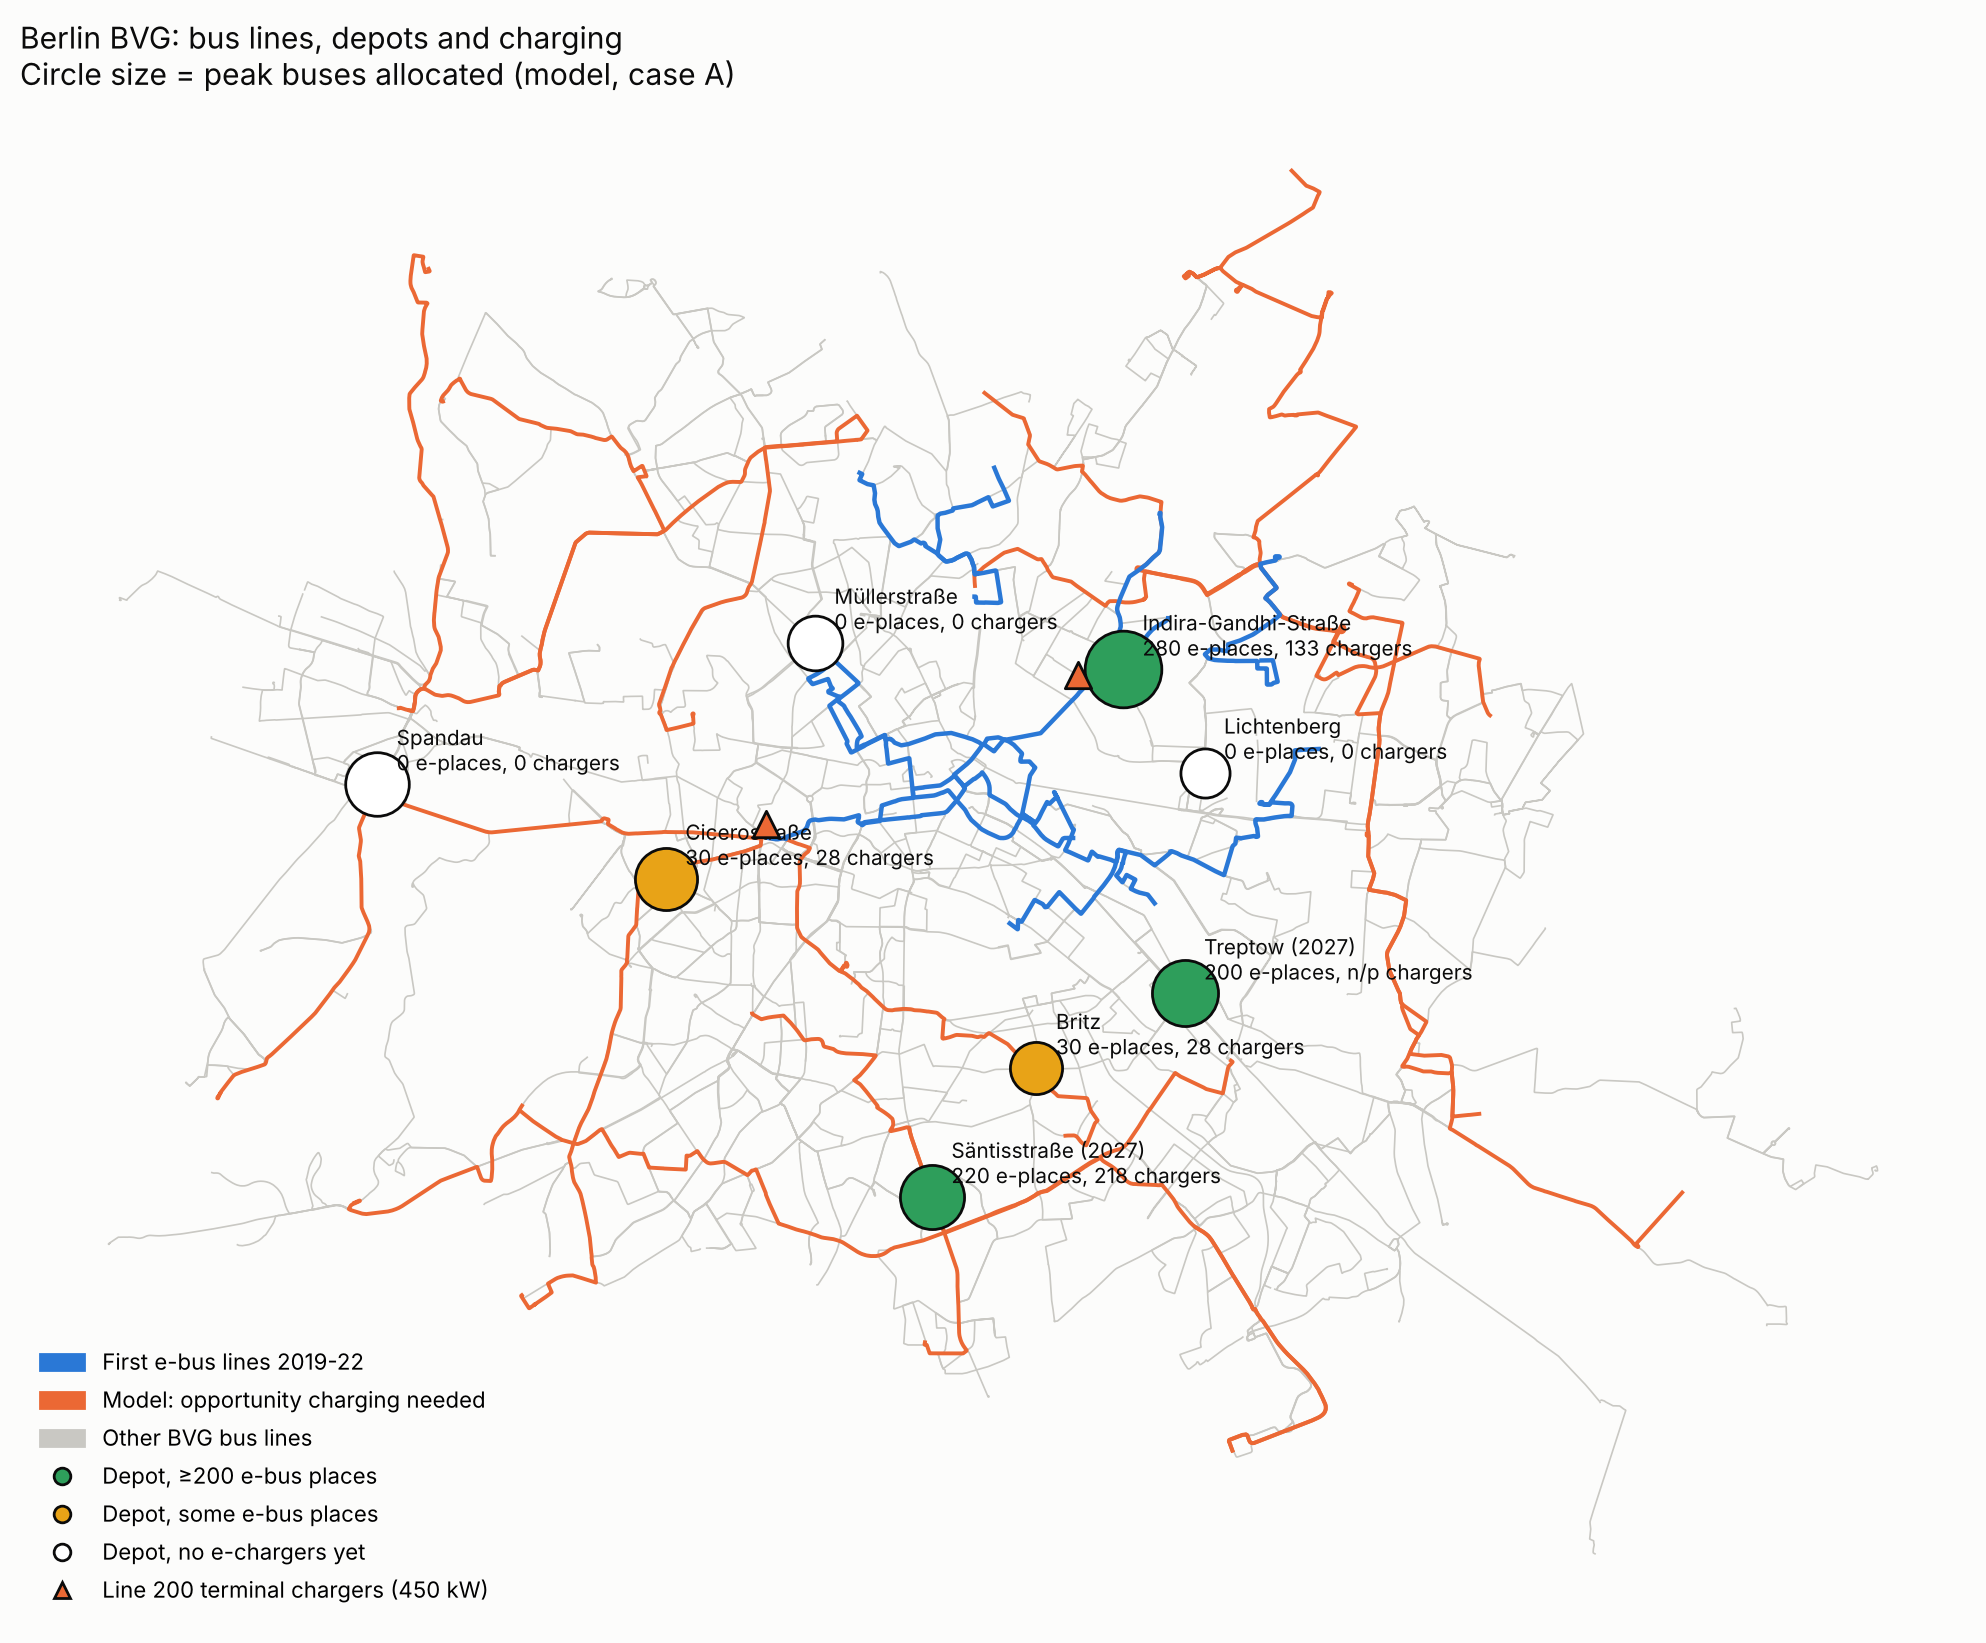

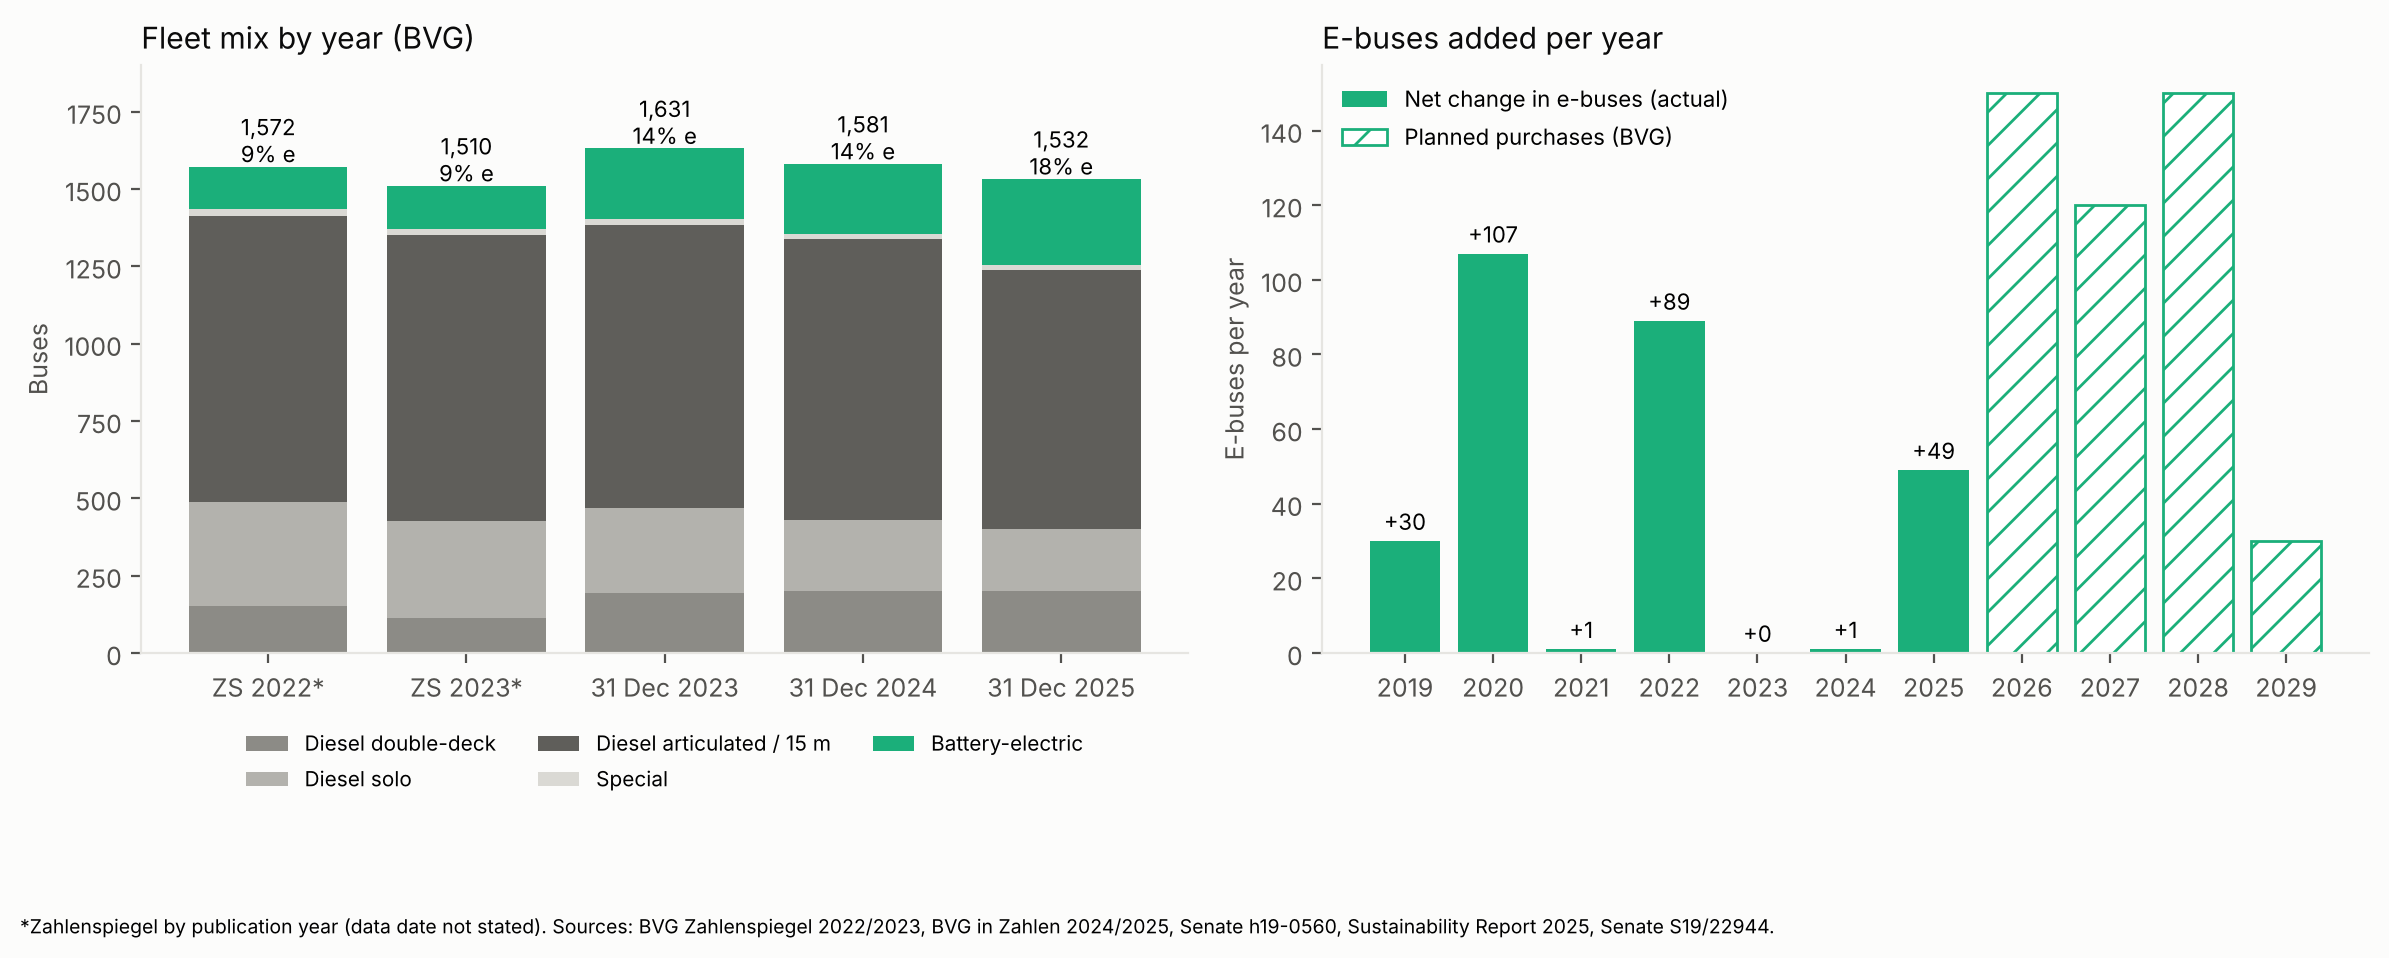

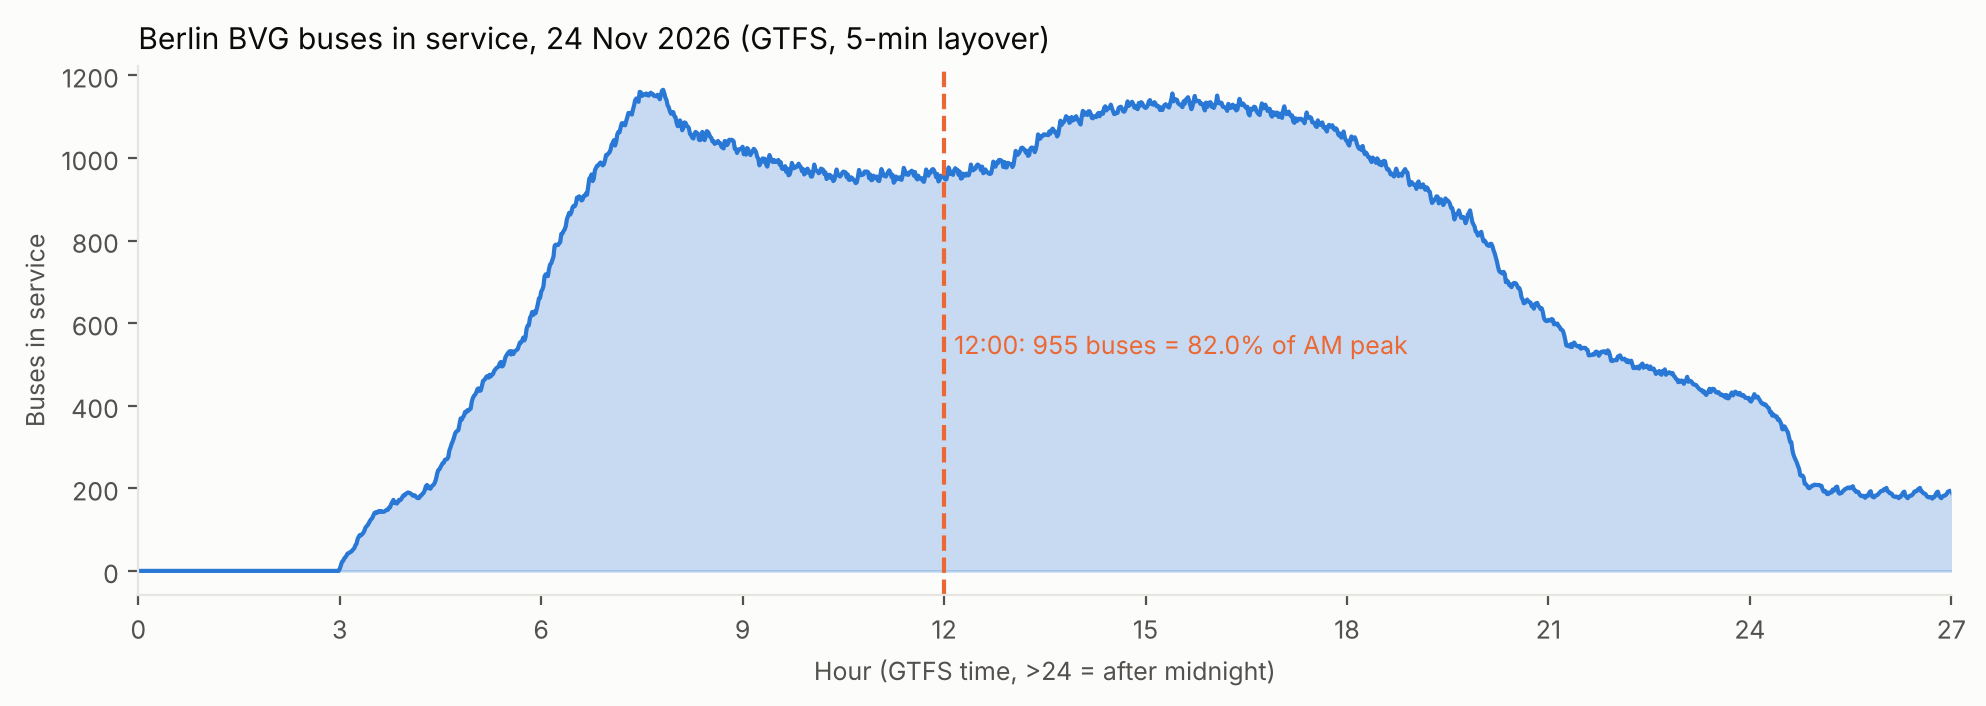

PASS Midday dip between 50% and 100%


In [23]:
# ---- 10g figures ----
import matplotlib.patches as mpatches
# (1) map: all lines, first e-lines, model opportunity lines, depots sized by e-bus places
opp = set(f2.loc[f2.charging_strategy != 'Depot', 'line_id'])
fig, ax = plt.subplots(figsize=(10, 8.5))
for line, sid in rep.items():
    g = geo[geo.shape_id == sid]
    if line in FIRST: c, lw, z = C1, 1.6, 3
    elif line in opp: c, lw, z = C2, 1.4, 2
    else: c, lw, z = '#c9c8c3', 0.6, 1
    ax.plot(g.lon, g.lat, color=c, lw=lw, zorder=z)
for _, r in dep.iterrows():
    size = 60 + 2.2 * max(r.peak_buses_model_caseA, 1)
    face = '#2e9e5b' if r.ebus_places >= 200 else ('#e8a317' if r.ebus_places > 0 else 'white')
    ax.scatter(r.longitude, r.latitude, s=size, color=face, edgecolor=INK, zorder=5)
    cp = 'n/p' if pd.isna(r.charging_points) else int(r.charging_points)
    ax.annotate(f"{r.depot}\n{int(r.ebus_places)} e-places, {cp} chargers", (r.longitude, r.latitude), xytext=(7, 5), textcoords='offset points', fontsize=7.5, color=INK, zorder=6)
for nm in ['Hertzallee', 'Michelangelostr']:
    m = stops[stops.stop_name.str.contains(nm, regex=False)]
    if len(m): ax.scatter(m.lon.iloc[0], m.lat.iloc[0], marker='^', s=90, color=C2, edgecolor=INK, zorder=6)
handles = [mpatches.Patch(color=C1, label='First e-bus lines 2019-22'), mpatches.Patch(color=C2, label='Model: opportunity charging needed'),
           mpatches.Patch(color='#c9c8c3', label='Other BVG bus lines'),
           plt.Line2D([], [], marker='o', ls='', mfc='#2e9e5b', mec=INK, label='Depot, ≥200 e-bus places'),
           plt.Line2D([], [], marker='o', ls='', mfc='#e8a317', mec=INK, label='Depot, some e-bus places'),
           plt.Line2D([], [], marker='o', ls='', mfc='white', mec=INK, label='Depot, no e-chargers yet'),
           plt.Line2D([], [], marker='^', ls='', mfc=C2, mec=INK, label='Line 200 terminal chargers (450 kW)')]
ax.legend(handles=handles, loc='lower left', fontsize=8, frameon=False)
ax.set_aspect(1 / np.cos(np.radians(52.5))); ax.set_axis_off()
ax.set_title('Berlin BVG: bus lines, depots and charging\nCircle size = peak buses allocated (model, case A)', loc='left')
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_depots_lines_map.png', dpi=200); plt.show()

# (2) fleet mix by year (official counts)
fm = pd.DataFrame({
 'ZS 2022*': [153, 336, 922, 23, 138], 'ZS 2023*': [113, 315, 922, 22, 138],
 '31 Dec 2023': [194, 276, 912, 22, 227], '31 Dec 2024': [199, 232, 907, 15, 228], '31 Dec 2025': [199, 202, 838, 16, 277]},
 index=['Diesel double-deck', 'Diesel solo', 'Diesel articulated / 15 m', 'Special', 'Battery-electric']).T
fm.to_csv(OUT_DIR / 'berlin_fleet_mix_by_year.csv')
cols = ['#8c8b86', '#b3b2ad', '#5f5e5a', '#dad9d4', C3]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
bottom = np.zeros(len(fm))
for c, col in zip(fm.columns, cols):
    ax[0].bar(fm.index, fm[c], bottom=bottom, color=col, label=c); bottom += fm[c].values
for i, (tot, e) in enumerate(zip(fm.sum(1), fm['Battery-electric'])):
    ax[0].text(i, tot + 15, f'{tot:,}\n{100 * e / tot:.0f}% e', ha='center', fontsize=8)
ax[0].set_ylim(0, 1900); ax[0].set_ylabel('Buses'); ax[0].legend(frameon=False, fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
ax[0].set_title('Fleet mix by year (BVG)', loc='left')
# (3) e-buses added per year
yrs = [2019, 2020, 2021, 2022, 2023, 2024, 2025]; stock = [30, 137, 138, 227, 227, 228, 277]
added = np.diff([0] + stock)
plan = {2026: 150, 2027: 120, 2028: 150, 2029: 30}
ax[1].bar(yrs, added, color=C3, label='Net change in e-buses (actual)')
ax[1].bar(list(plan), list(plan.values()), color='white', edgecolor=C3, hatch='//', label='Planned purchases (BVG)')
for x, y in zip(yrs, added): ax[1].text(x, y + 3, f'+{y}', ha='center', fontsize=8)
ax[1].set_ylabel('E-buses per year'); ax[1].legend(frameon=False, fontsize=8); ax[1].set_xticks(yrs + list(plan))
ax[1].set_title('E-buses added per year', loc='left')
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.12, '*Zahlenspiegel by publication year (data date not stated). Sources: BVG Zahlenspiegel 2022/2023, BVG in Zahlen 2024/2025, Senate h19-0560, Sustainability Report 2025, Senate S19/22944.', fontsize=7)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_fleet_mix_and_pace.png', dpi=200, bbox_inches='tight'); plt.show()

# (4) vehicles in service over the day, midday dip
fig, ax = plt.subplots(figsize=(10, 3.6))
h = vc.minute / 60
ax.fill_between(h, vc.vehicles, color=C1, alpha=0.25); ax.plot(h, vc.vehicles, color=C1)
ax.axvline(12, color=C2, ls='--'); ax.text(12.15, noon * 0.55, f'12:00: {noon:.0f} buses = {midday_dip_pct}% of AM peak', color=C2, fontsize=9)
ax.set_xlim(0, 27); ax.set_xticks(range(0, 28, 3)); ax.set_xlabel('Hour (GTFS time, >24 = after midnight)'); ax.set_ylabel('Buses in service')
ax.spines[['top', 'right']].set_visible(False); ax.set_title('Berlin BVG buses in service, 24 Nov 2026 (GTFS, 5-min layover)', loc='left')
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_midday_dip.png', dpi=200); plt.show()
ok('Midday dip between 50% and 100%', 50 < midday_dip_pct <= 100)

## 10h. Benchmark in the team format (same definitions as Helsinki and Brussels)
The Helsinki and Brussels notebooks compare cities on one set of definitions. This section puts Berlin on exactly those definitions, so the four cities can be read side by side:

* **Peak vehicles** = network peak of concurrent trips plus the terminus layover (Helsinki method; a lower bound), shown for 5 / 10 / 15 min. Not the sum of line peaks used for File 2.
* **Midday share** = vehicles in service at 12:00 as % of the city's own peak.
* **Energy** = daily bus-km x 1.30 kWh/km, every bus treated as standard (the brief's benchmark convention). The articulated case is the sensitivity.
* **Opportunity lines** = lines above 300 km per bus per day (all standard), with the articulated sensitivity (240 km).

Madrid and Brussels come from `../Brussels/outputs/` (master branch). Helsinki comes from `Helsinki/outputs/benchmark_helsinki_madrid_brussels.csv` on the Helsinki branch (commit a214094); its values are typed below because that folder is not on this branch.

In [24]:
# ---- Berlin on the team's benchmark definitions ----
pk = {lay: int(net[lay]) for lay in (5, 10, 15)}
curve5 = curve(tt, 5)
mid_pct = 100 * curve5[12 * 60] / curve5.max()
lp = {lay: tt.groupby('route_short_name').apply(lambda x: int(curve(x, lay).max())).clip(lower=1) for lay in (5, 10, 15)}
km_line = daily.set_index('route_short_name').daily_km
opp_std = {lay: int(((km_line / lp[lay]) > 300).sum()) for lay in (5, 10, 15)}
opp_art = int((f2.km_per_bus_day > np.where(f2.bus_type == 'Articulated', 240, 300)).sum())
berlin = pd.Series({
    'Bus lines (weekday)': len(f2), 'Daily bus-km': round(daily_km),
    'Peak vehicles in service (GTFS blocks)': pk[5],
    'km per peak vehicle per day (blocks)': round(daily_km / pk[5], 1),
    'Midday vehicles as % of peak': round(mid_pct, 1),
    '100% BEB energy (MWh/day)': round(daily_km * 1.30 / 1000, 1),
    'Lines needing opportunity charging': opp_std[5],
    'Fleet total': FLEET_TOTAL, 'Zero-emission share of fleet (%)': round(100 * (N_BEV + N_H2) / FLEET_TOTAL, 1)})

bpath = Path('../Brussels/outputs/benchmark_madrid_vs_brussels.csv')
bench4 = pd.read_csv(bpath, index_col=0)[['Madrid (EMT)', 'Brussels (STIB)']] if bpath.exists() else pd.DataFrame(index=berlin.index)
bench4 = bench4.reindex(berlin.index.union(bench4.index, sort=False))
# Helsinki branch, Helsinki/outputs/benchmark_helsinki_madrid_brussels.csv (commit a214094)
HEL = {'Bus lines (weekday)': 390, 'Daily bus-km': 289735, 'Peak vehicles in service (GTFS blocks)': 1041, 'km per peak vehicle per day (blocks)': 278.3,
       'Midday vehicles as % of peak': 67.0, '100% BEB energy (MWh/day)': 376.7, 'Lines needing opportunity charging': 25, 'Fleet total': 1154, 'Zero-emission share of fleet (%)': 52.0}
TEAM_FLEET = {'Madrid (EMT)': (2210, 20.9), 'Brussels (STIB)': (850, 16.8)}   # Helsinki benchmark CSV
for c, (ft, ze) in TEAM_FLEET.items():
    if c in bench4:
        bench4.loc['Fleet total', c] = ft; bench4.loc['Zero-emission share of fleet (%)', c] = ze
bench4['Helsinki (HSL)'] = pd.Series(HEL); bench4['Berlin (BVG)'] = berlin
if 'Madrid (EMT)' in bench4: bench4['Berlin / Madrid'] = (bench4['Berlin (BVG)'] / bench4['Madrid (EMT)']).round(2)
bench4.to_csv(OUT_DIR / 'benchmark_berlin_madrid_brussels_helsinki.csv')
print(bench4.to_string())
print(f"\nBerlin sensitivities: peak vehicles {pk[5]} / {pk[10]} / {pk[15]} (5 / 10 / 15 min layover);"
      f" opportunity lines {opp_std[5]} / {opp_std[10]} / {opp_std[15]} (all standard), {opp_art} with articulated buses at 240 km")
ok('Berlin benchmark row complete', berlin.notna().all())

                                            Madrid (EMT)  Brussels (STIB)  Helsinki (HSL)  Berlin (BVG)  Berlin / Madrid
Bus lines (weekday)                                234.0             51.0           390.0         215.0             0.92
Daily bus-km                                    339331.0          91639.0        289735.0      291764.0             0.86
Peak vehicles in service (GTFS blocks)            1937.0            616.0          1041.0        1165.0             0.60
km per peak vehicle per day (blocks)               175.2            148.8           278.3         250.4             1.43
Midday vehicles as % of peak                        90.8             64.3            67.0          82.0             0.90
100% BEB energy (MWh/day)                          447.2            133.4           376.7         379.3             0.85
Lines needing opportunity charging                   6.0              4.0            25.0           6.0             1.00
Fleet total                     

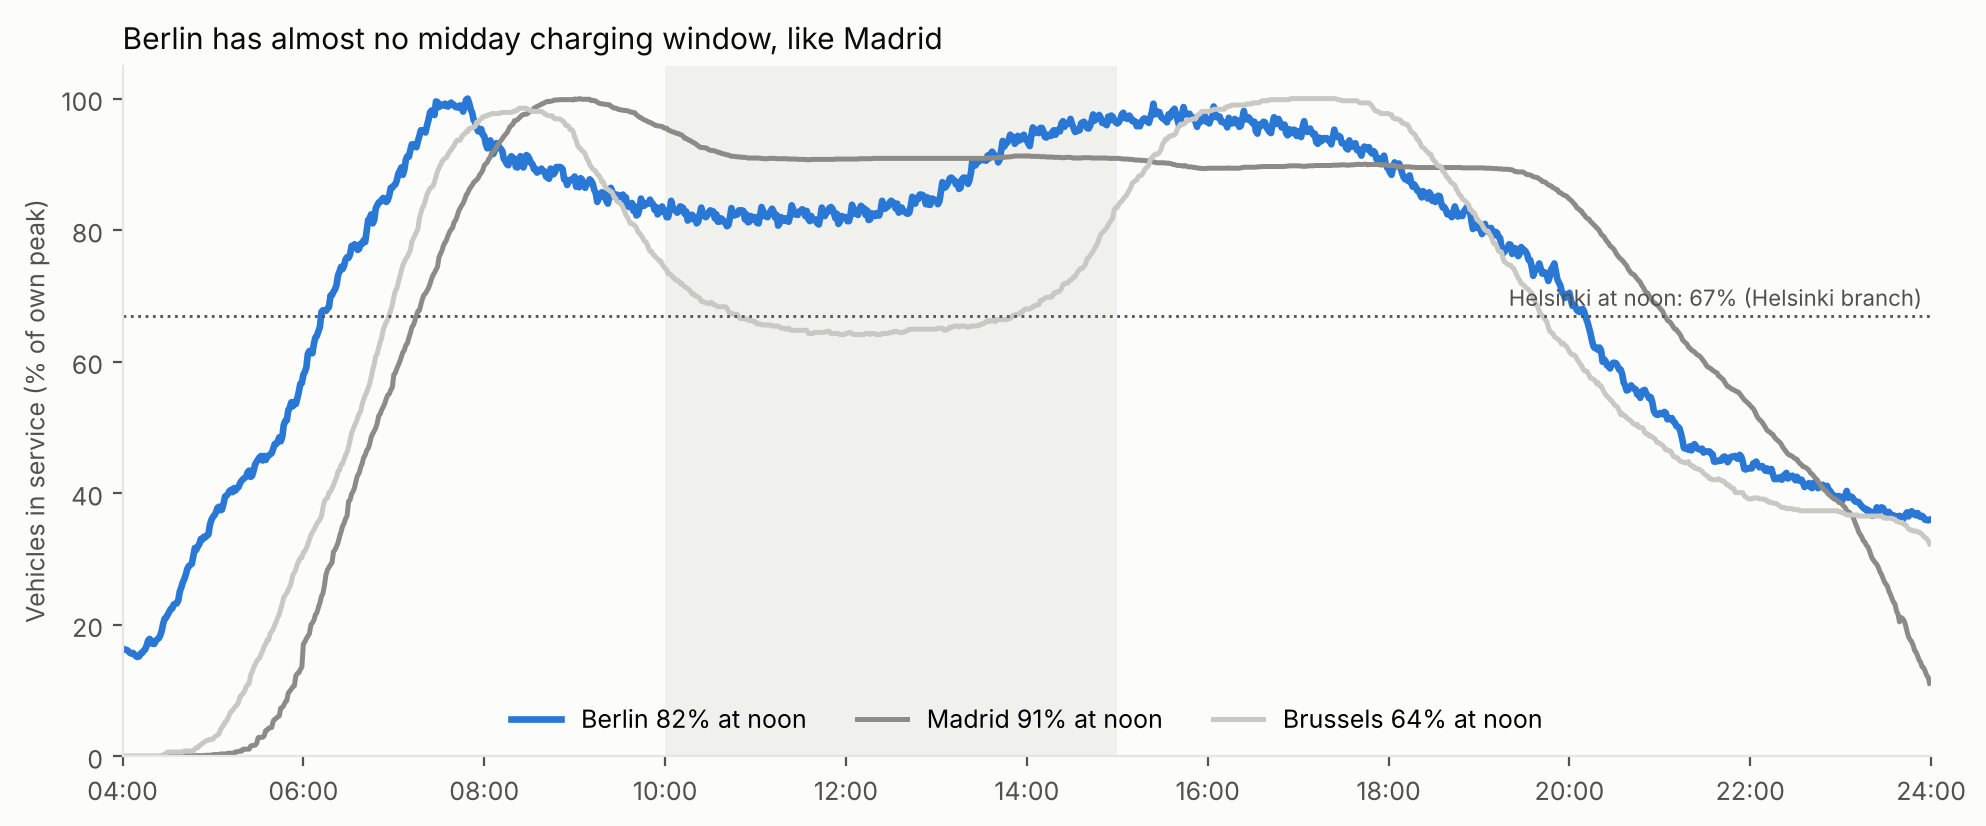

In [25]:
# ---- vehicles in service by hour, % of own peak: four cities ----
ppath = Path('../Brussels/outputs/vehicles_in_service_by_minute.csv')
series = [('Berlin (BVG)', curve5[:24 * 60], C1)]
if ppath.exists():
    prof = pd.read_csv(ppath)
    series += [('Madrid (EMT)', prof.madrid.values[:24 * 60], '#8c8b86'), ('Brussels (STIB)', prof.brussels.values[:24 * 60], '#c9c8c3')]
hrs = np.arange(24 * 60) / 60
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, cur, col in series:
    pct = 100 * cur / cur.max()
    ax.plot(hrs[:len(pct)], pct, color=col, lw=2.4 if name.startswith('Berlin') else 1.8, label=f"{name.split(' ')[0]} {pct[12 * 60]:.0f}% at noon")
ax.axhline(HEL['Midday vehicles as % of peak'], color=INK2, ls=':', lw=1)
ax.text(23.9, HEL['Midday vehicles as % of peak'] + 1.5, f"Helsinki at noon: {HEL['Midday vehicles as % of peak']:.0f}% (Helsinki branch)", fontsize=8, color=INK2, ha='right')
ax.axvspan(10, 15, color=GRID, alpha=0.5, lw=0)
ax.set_xlim(4, 24); ax.set_ylim(0, 105); ax.set_xticks(range(4, 25, 2)); ax.set_xticklabels([f'{h:02d}:00' for h in range(4, 25, 2)])
ax.set_ylabel('Vehicles in service (% of own peak)'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower center', ncol=3, fontsize=9)
ax.set_title('Berlin has almost no midday charging window, like Madrid', loc='left')
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_berlin_vs_cities_by_hour.png', dpi=200); plt.show()

## 10i. Key findings for the benchmark (Berlin vs Madrid, Brussels, Helsinki)
*Numbers from this run (Berlin: Tue 24 Nov 2026). Madrid, Brussels and Helsinki values from the team's notebooks, same definitions (Section 10h).*

1. **Berlin runs as much service as Helsinki with fewer buses on the road than Madrid.** 292k bus-km a day (0.86x Madrid, equal to Helsinki) with a network peak of 1,165 buses (0.60x Madrid's 1,937; 1,310-1,464 with 10-15 min layovers). Each Berlin bus runs **250 km a day**, against 175 km in Madrid. Berlin works its buses harder, so range matters more than in Madrid.

2. **Like Madrid, Berlin has almost no midday charging window.** At noon 82% of Berlin's peak buses are still in service, close to Madrid (91%) and far from Helsinki (67%) and Brussels (64%). Berlin cannot lean on daytime depot charging, which explains why it is building terminal fast chargers (line 200 since 2020; STELLA, up to 20 terminals by 2027). **Of the three benchmarks, Berlin is the closest to Madrid's operating profile**, so its charging answers are the most transferable.

3. **The range problem is the articulated fleet, not the network.** With every bus treated as standard, only 6 lines exceed 300 km per bus (the same as Madrid). With Berlin's real fleet (73% of peak buses articulated, 240 km range) it is 17 lines. Berlin's answer is bigger batteries: the 270 Solaris Urbino 18 on order carry about 700 kWh.

4. **The energy scale is similar to Helsinki and below Madrid.** 379 MWh a day at the benchmark's 1.30 kWh/km (0.85x Madrid). With articulated buses at 1.85 kWh/km it rises to 510 MWh a night, above Madrid.

5. **Berlin shows what a slow, budget-driven pace looks like.** 18% zero-emission (277 of 1,532) against Helsinki's 52%. Helsinki fixes a minimum electric share in every bus tender; Berlin buys from a yearly Land budget, and after the 2024 cut (EUR 33.1M to EUR 8M) it added one e-bus in two years. *Lesson for Madrid:* tie the pace to contracts or multi-year funding, not to one year's budget.

6. **Berlin's depot answer is new e-only depots.** Two new depots (Saentisstrasse, Treptow; about 420 e-bus places, about one charger per bus) open in 2027, so no depot in service has to close for conversion. In the model this takes Berlin from 1 Critical and 5 Upgrade depots today to 0 Critical in the end state. *Lesson for Madrid:* adding capacity beside the network is what avoids a La Elipa-type closure.

**Caveats**
- Peak vehicles are a lower bound (no `block_id` on 88% of trips), as in Helsinki.
- Berlin per-depot grid capacity is published only for Indira-Gandhi-Strasse; the readiness results use a 10-13 MVA range.

## 11. Assumptions register (V / D / P / A)

In [26]:
reg = pd.DataFrame([
 ['B01', 'Reference date', REFERENCE_DATE + ' (Tuesday)', 'D', 'Inside the feed; no Berlin holiday; trip count equal to nearby weekdays', 'Timetable, km', 'Re-check strikes once the day has passed.'],
 ['B02', 'Perimeter', 'BVG agency 796, route_type 700', 'D', 'Includes subcontracted lines and rail-replacement buses (' + ', '.join(REPLACEMENT) + ')', 'All', 'Replacement services are temporary; listed.'],
 ['B03', 'Trip length', 'haversine length of the trip shape', 'D', 'No shape_dist_traveled in the feed; stop-to-stop check below 1 as expected', 'Daily km', 'Section 4.'],
 ['B04', 'In-service km only', 'no deadheading', 'A', 'GTFS has no depot runs', 'Energy, range', 'Same limitation as Madrid.'],
 ['B05', 'peak_buses', f'peak concurrent trips + {LAYOVER_MIN}-min layover', 'P', 'No supply file; block_id on 12% of trips only', 'Buses, km per bus', 'Layover 0/10/15 in Section 8.'],
 ['B06', 'Fleet baseline', f'{FLEET_TOTAL} = {N_BEV} BEV + {N_DIESEL} diesel', 'V', 'BVG in Zahlen 2025; special vehicles counted as diesel (A)', 'File 1, File 4', '278 e-buses in the Sustainability Report.'],
 ['B07', 'Bus type per line', f'line type then size, until {100*ART_SHARE_FLEET:.1f}% of peak buses', 'P / A', 'No passenger data per line; double-deckers treated as Articulated', 'Energy, strategy', 'Validation lines in Section 7.'],
 ['B08', 'Opportunity limit', f'{OPP_MAX} x range', 'A', 'As Madrid', 'Strategy', '1.5x / 2.5x in Section 8.'],
 ['B09', 'Depot positions', 'GTFS depot stops; 4 nearest-stop proxies', 'D / P', 'Check on a map', 'Allocation, File 3', ''],
 ['B10', 'Depot allocation', 'capacity-constrained nearest depot', 'P', 'No public line-to-depot table', 'Depot totals', 'Validated against the 2023 Indira-Gandhi-Straße lines (Section 9).'],
 ['B11', 'Depot capacities', 'B: buses today (enthusiast); A: BVG planned e-bus places 2022', 'P', 'Federal evaluation p. 300; depot "F" excluded', 'Allocation', 'Later sources: Treptow ~200-220, Säntisstraße ~220.'],
 ['B12', 'New depots open', str(NEW_DEPOTS_OPEN), 'V', 'BVG / Senate S19/22944: April 2027', 'Timeline', 'Treptow second site 2028 not modelled separately.'],
 ['B13', 'Fixed parameters', '1.30 / 1.85 kWh/km; 300 / 240 km; 100 kW; 7 h; 90%', 'V', 'Brief Section 4.5, as Madrid', 'All energy', 'Measured German values: 1.32 / 1.70 kWh/km, 85.9% charger efficiency.'],
 ['B14', 'Diesel consumption', '0.37 / 0.50 l/km', 'V', 'Federal e-bus evaluation table 39', 'CO2', ''],
 ['B15', 'Diesel CO2 factor', f'{DIESEL_CO2_KG_PER_L} kg CO2e/l (WTW)', 'V', 'BVG Sustainability Report 2025 p. 42', 'CO2', 'TTW 2.65 kg/l tested; boundary differs from Madrid.'],
 ['B16', 'Electricity CO2 factor', f'{ELEC_CO2_KG_PER_KWH} kg/kWh', 'V', 'UBA, German mix 2025', 'CO2', 'Green contract (0) and 2030 path (0.254) tested.'],
 ['B17', 'Connection power', '10 MVA (low, base) / 13 MVA (high); IGS 10 MW evidenced', 'V / P', 'Senate h19-2626; NOW 2020', 'Readiness', 'No per-depot contract published.'],
 ['B18', 'S0 path', f'BVG plan to 2029, then {S0_PACE_2030_35}/yr to 85% in 2035', 'V / A', 'BVG Sustainability Report 2025 p. 39', 'File 4', '2026/27 split 135/135 assumed.'],
 ['B19', 'Fleet constant, no new diesel', str(FLEET_TOTAL), 'A', 'No vehicle ages published', 'File 4', 'BVG target fleet ~1,600.'],
 ['B20', 'Capex unit costs', 'EUR 571k / 815k per bus, EUR 103k charging per bus', 'D', 'BVG 2020-21 (federal evaluation table 25); Solaris order 2025', 'Capex', 'Depot construction and grid connections excluded.'],
], columns=['id', 'item', 'value', 'class', 'evidence', 'affects', 'test / note'])
print(reg.to_string(index=False))
reg.to_csv(OUT_DIR / 'berlin_assumptions_register.csv', index=False)

 id                          item                                                         value class                                                                              evidence            affects                                                           test / note
B01                Reference date                                          2026-11-24 (Tuesday)     D               Inside the feed; no Berlin holiday; trip count equal to nearby weekdays      Timetable, km                             Re-check strikes once the day has passed.
B02                     Perimeter                                BVG agency 796, route_type 700     D Includes subcontracted lines and rail-replacement buses (12, 21, 27, M17, M8, U2, U6)                All                           Replacement services are temporary; listed.
B03                   Trip length                            haversine length of the trip shape     D            No shape_dist_traveled in the feed; stop-to-stop check b

## 12. Regression checks
Reference values from the validated run of this notebook (19 Nov 2026). Any FAIL means the inputs or the code changed.

In [27]:
def check(name, got, expected):
    print(('PASS ' if got == expected else 'FAIL ') + f'{name}: got {got!r}, expected {expected!r}')
REGRESSION = {'trips': 29209, 'lines': 215, 'daily_km': 291764, 'peak_buses': 1572, 'strategy': {'Depot': 198, 'Opportunity': 17}, 'depot_A': {'Britz': 133, 'Cicerostraße': 200, 'Indira-Gandhi-Straße': 319, 'Lichtenberg': 115, 'Müllerstraße': 149, 'Spandau': 211, 'Säntisstraße': 215, 'Treptow': 230}, 'readiness': {'Indira-Gandhi-Straße': 'Upgrade', 'Britz': 'Ready', 'Cicerostraße': 'Upgrade', 'Lichtenberg': 'Ready', 'Müllerstraße': 'Ready', 'Spandau': 'Upgrade', 'Säntisstraße': 'Upgrade', 'Treptow': 'Ready'}}
check('Trips on the reference day', len(t_ref), REGRESSION['trips'])
check('Lines in File 2', len(f2), REGRESSION['lines'])
check('Total daily km (rounded)', int(round(f2.daily_km.sum())), REGRESSION['daily_km'])
check('Total peak buses', int(f2.peak_buses.sum()), REGRESSION['peak_buses'])
check('Charging strategy', f2.charging_strategy.value_counts().to_dict(), REGRESSION['strategy'])
check('Peak buses per depot, case A', {k: int(v) for k, v in f2.groupby('depot_A').peak_buses.sum().items()}, REGRESSION['depot_A'])
check('Readiness, case A', f3.readiness_status.to_dict(), REGRESSION['readiness'])

PASS Trips on the reference day: got 29209, expected 29209
PASS Lines in File 2: got 215, expected 215
PASS Total daily km (rounded): got 291764, expected 291764
PASS Total peak buses: got 1572, expected 1572
PASS Charging strategy: got {'Depot': 198, 'Opportunity': 17}, expected {'Depot': 198, 'Opportunity': 17}
PASS Peak buses per depot, case A: got {'Britz': 133, 'Cicerostraße': 200, 'Indira-Gandhi-Straße': 319, 'Lichtenberg': 115, 'Müllerstraße': 149, 'Spandau': 211, 'Säntisstraße': 215, 'Treptow': 230}, expected {'Britz': 133, 'Cicerostraße': 200, 'Indira-Gandhi-Straße': 319, 'Lichtenberg': 115, 'Müllerstraße': 149, 'Spandau': 211, 'Säntisstraße': 215, 'Treptow': 230}
PASS Readiness, case A: got {'Indira-Gandhi-Straße': 'Upgrade', 'Britz': 'Ready', 'Cicerostraße': 'Upgrade', 'Lichtenberg': 'Ready', 'Müllerstraße': 'Ready', 'Spandau': 'Upgrade', 'Säntisstraße': 'Upgrade', 'Treptow': 'Ready'}, expected {'Indira-Gandhi-Straße': 'Upgrade', 'Britz': 'Ready', 'Cicerostraße': 'Upgrade', 

## 13. Open items before submission
* **Connection MW per depot**: only Indira-Gandhi-Straße is documented (10 MW, 2020). The result of Stromnetz Berlin's allocation round (postponed by a court case, upheld 4 Nov 2026) would replace the 10-13 MVA range.
* **Line-to-depot allocation** is a rule, not data. If the team obtains BVG's line list per depot, replace Section 9 with it.
* **Depot positions** for Cicerostraße, Müllerstraße, Säntisstraße and Treptow are nearest-stop proxies: check on a map.
* **Charging window**: the 7 h of the brief is kept; Berlin runs a large night network (68 night lines), so the real window may be shorter (Section 10e-2 shows 5-8 h).
* **Sources** for every input are listed in `data/README.md` and in the assumptions register.